In [ ]:
# ============================================================
# DOSM DATATHON 2026
# SUSTAINABLE TOURISM READINESS IN MALAYSIA
# ============================================================

!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl pyarrow requests

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    silhouette_score,
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

print("Environment ready.")

Environment ready.


In [ ]:
# ============================================================
# PROJECT FOLDERS
# ============================================================

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Folders created.")

Folders created.


In [ ]:
URLS = {

    # Economic
    "gdp":
    "https://storage.dosm.gov.my/gdp/gdp_state_real_supply.csv",

    # Household income / poverty / inequality / expenditure
    "hies":
    "https://storage.dosm.gov.my/hies/hies_state.csv",

    # Labour
    "labour":
    "https://storage.dosm.gov.my/labour/lfs_state_sex.csv",

    # Population
    "population":
    "https://storage.dosm.gov.my/population/population_state.csv",

    # CPI
    "cpi":
    "https://storage.dosm.gov.my/cpi/cpi_2d_state.csv",

    # Environment
    "forest":
    "https://storage.data.gov.my/environment/forest_reserve_state.csv",

    "water_access":
    "https://storage.data.gov.my/water/water_access.csv",

    "water_consumption":
    "https://storage.data.gov.my/water/water_consumption.csv"

    # The tourism URLs are removed as they will be loaded locally.
}

for name, url in URLS.items():
    print(name, ":", url)

gdp : https://storage.dosm.gov.my/gdp/gdp_state_real_supply.csv
hies : https://storage.dosm.gov.my/hies/hies_state.csv
labour : https://storage.dosm.gov.my/labour/lfs_state_sex.csv
population : https://storage.dosm.gov.my/population/population_state.csv
cpi : https://storage.dosm.gov.my/cpi/cpi_2d_state.csv
forest : https://storage.data.gov.my/environment/forest_reserve_state.csv
water_access : https://storage.data.gov.my/water/water_access.csv
water_consumption : https://storage.data.gov.my/water/water_consumption.csv


In [ ]:
import pandas as pd
import os
import requests
from io import StringIO, BytesIO

# ============================================================
# DOWNLOAD DATA
# ============================================================

raw_data = {}

os.makedirs("data/raw", exist_ok=True) # Ensure directory exists

# Define local file paths for tourism data
LOCAL_TOURISM_FILES = {
    "hotel_guest_international": "/content/data/raw/2015 2022 MALAYSIA INTERNATIONAL HOTEL GUESTS  .csv",
    # "hotel_guest_domestic": "/content/Malaysia Domestic Hotel Guests by State.xlsx", # Removed as per user request
    "hotel_aor": "/content/data/raw/_202306010434400_2015-2022-malaysia-average-occupancy-rates-by-state.csv"
}

# First, try to load tourism data from local files
for name, path in LOCAL_TOURISM_FILES.items():
    if os.path.exists(path):
        try:
            print(f"Loading local file {name} from {path}...")
            if path.endswith('.xlsx'):
                df = pd.read_excel(path)
            else:
                df = pd.read_csv(path)
            raw_data[name] = df
            print(f"   \u2713 {name}: {df.shape[0]:,} rows \u00d7 {df.shape[1]} columns")
        except Exception as e:
            print(f"   \u2717 Failed to load local file {name}: {e}")
    else:
        print(f"   \u2717 Local file for {name} not found at {path}.")

# Then, proceed with downloading other data from URLs
for name, url in URLS.items():
    # Skip if already loaded locally (shouldn't happen with current URLS dict, but good for robustness)
    if name in raw_data:
        continue

    try:
        print(f"Downloading {name}...")

        response = requests.get(url, timeout=60)
        response.raise_for_status() # Raise an exception for HTTP errors

        if url.endswith('.xlsx'):
            df = pd.read_excel(BytesIO(response.content))
            file_extension = '.xlsx'
        else:
            df = pd.read_csv(StringIO(response.text))
            file_extension = '.csv'

        raw_data[name] = df

        df.to_csv(
            f"data/raw/{name}{file_extension}", # Save with correct extension
            index=False
        )

        print(
            f"   \u2713 {name}: "
            f"{df.shape[0]:,} rows \u00d7 "
            f"{df.shape[1]} columns"
        )

    except requests.exceptions.Timeout:
        print(f"   \u2717 Failed: {name} - Request timed out after 60 seconds.")
    except requests.exceptions.RequestException as e:
        print(f"   \u2717 Failed: {name} - Network error: {e}")
    except Exception as e:
        print(
            f"   \u2717 Failed: {name}"
        )
        print(e)

Loading local file hotel_guest_international from /content/data/raw/2015 2022 MALAYSIA INTERNATIONAL HOTEL GUESTS  .csv...
   ✓ hotel_guest_international: 8 rows × 18 columns
Loading local file hotel_aor from /content/data/raw/_202306010434400_2015-2022-malaysia-average-occupancy-rates-by-state.csv...
   ✓ hotel_aor: 8 rows × 18 columns
   ✓ gdp: 2,163 rows × 5 columns
   ✓ hies: 32 rows × 7 columns
   ✓ labour: 1,732 rows × 10 columns
   ✓ population: 270,063 rows × 6 columns
   ✓ cpi: 44,800 rows × 4 columns
   ✓ forest: 323 rows × 3 columns
   ✓ water_access: 1,035 rows × 4 columns
   ✓ water_consumption: 600 rows × 4 columns


In [ ]:
# ============================================================
# INSPECT DATA
# ============================================================

for name, df in raw_data.items():

    print("\n" + "=" * 70)

    print(name.upper())

    print("=" * 70)

    print(df.columns.tolist())

    display(df.head(3))


HOTEL_GUEST_INTERNATIONAL
['YEAR ', 'KUALA LUMPUR', 'PUTRAJAYA', 'SELANGOR', 'PENANG', 'PERAK', 'KEDAH', 'PERLIS', 'N. SEMBILAN', 'MELAKA', 'JOHOR', 'PAHANG ', 'TERENGGANU ', 'KELANTAN ', 'SABAH ', 'LABUAN ', 'SARAWAK ', 'TOTAL ']


,YEAR,KUALA LUMPUR,PUTRAJAYA,SELANGOR,PENANG,PERAK,KEDAH,PERLIS,N. SEMBILAN,MELAKA,JOHOR,PAHANG,TERENGGANU,KELANTAN,SABAH,LABUAN,SARAWAK,TOTAL
0,2015,"9,341,801","151,740","1,613,299","2,879,899","265,794","1,207,824","5,921","456,013","1,809,489","2,565,092","2,328,815","187,388","58,327","1,986,136","114,140","599,400","25,571,078"
1,2016,"9,436,404","166,473","1,624,265","2,911,783","267,517","1,281,471","5,946","459,966","1,804,544","2,581,983","2,369,945","192,530","57,664","2,036,610","111,815","599,985","25,908,901"
2,2017,"10,717,479","177,602","1,688,659","2,911,429","267,245","1,407,261","5,943","461,788","1,704,386","2,624,972","2,563,991","188,044","57,337","2,548,491","105,710","599,812","28,030,149"



HOTEL_AOR
['YEAR ', 'KUALA LUMPUR', 'PUTRAJAYA', 'SELANGOR', 'PENANG', 'PERAK', 'KEDAH', 'PERLIS', 'N. SEMBILAN', 'MELAKA', 'JOHOR', 'PAHANG ', 'TERENGGANU ', 'KELANTAN ', 'SABAH ', 'LABUAN ', 'SARAWAK ', 'TOTAL ']


,YEAR,KUALA LUMPUR,PUTRAJAYA,SELANGOR,PENANG,PERAK,KEDAH,PERLIS,N. SEMBILAN,MELAKA,JOHOR,PAHANG,TERENGGANU,KELANTAN,SABAH,LABUAN,SARAWAK,TOTAL
0,2015,67.100,65.700,64.700,63.700,51.300,54.900,44.400,47.900,63.300,58.500,79.300,48.700,40.900,64.200,66.200,57.900,61.900
1,2016,66.100,70.600,62.400,63.900,49.000,59.500,36.500,52.800,59.900,61.000,74.600,45.000,43.800,64.500,55.300,53.400,60.900
2,2017,66.100,73.900,60.300,62.100,46.300,60.300,35.400,55.700,60.000,62.500,75.700,45.200,43.800,65.300,52.600,52.600,60.600



GDP
['series', 'date', 'state', 'sector', 'value']


...

,date,state,area
0,2003-01-01,Johor,"356,922.000"
1,2003-01-01,Kedah,"344,530.000"
2,2003-01-01,Kelantan,"629,687.000"



WATER_ACCESS
['state', 'strata', 'date', 'proportion']


,state,strata,date,proportion
0,Malaysia,overall,2000-01-01,92.000
1,Malaysia,overall,2001-01-01,92.700
2,Malaysia,overall,2002-01-01,93.200



WATER_CONSUMPTION
['state', 'sector', 'date', 'value']


,state,sector,date,value
0,Malaysia,domestic,2003-01-01,4394
1,Malaysia,domestic,2004-01-01,4770
2,Malaysia,domestic,2005-01-01,4992


In [ ]:
# ============================================================
# STATE STANDARDISATION
# ============================================================

STATE_MAP = {

    "Johor": "Johor",
    "Johore": "Johor",

    "Kedah": "Kedah",

    "Kelantan": "Kelantan",

    "Melaka": "Melaka",
    "Malacca": "Melaka",

    "Negeri Sembilan": "Negeri Sembilan",
    "N. Sembilan": "Negeri Sembilan", # Added this mapping

    "Pahang": "Pahang",

    "Pulau Pinang": "Pulau Pinang",
    "Penang": "Pulau Pinang",

    "Perak": "Perak",

    "Perlis": "Perlis",

    "Selangor": "Selangor",

    "Terengganu": "Terengganu",

    "Sabah": "Sabah",

    "Sarawak": "Sarawak",

    "W.P. Kuala Lumpur": "W.P. Kuala Lumpur",
    "Kuala Lumpur": "W.P. Kuala Lumpur",

    "W.P. Putrajaya": "W.P. Putrajaya",
    "Putrajaya": "W.P. Putrajaya",

    "W.P. Labuan": "W.P. Labuan",
    "Labuan": "W.P. Labuan"
}

def clean_state_column(df):

    df = df.copy()

    if "state" in df.columns:

        df["state"] = (
            df["state"]
            .astype(str)
            .str.strip()
            .replace(STATE_MAP)
        )

    return df


for name in raw_data:

    raw_data[name] = clean_state_column(
        raw_data[name]
    )

print("State names standardised.")

State names standardised.


In [ ]:
# ============================================================
# DATE STANDARDISATION
# ============================================================

def add_year(df):

    df = df.copy()

    if "date" in df.columns:

        df["date"] = pd.to_datetime(
            df["date"],
            errors="coerce"
        )

        df["year"] = df["date"].dt.year

    return df


for name in raw_data:

    raw_data[name] = add_year(
        raw_data[name]
    )

In [ ]:
hies = raw_data["hies"].copy()

print(hies.columns.tolist())

display(hies.head())

['date', 'state', 'income_mean', 'income_median', 'expenditure_mean', 'gini', 'poverty', 'year']


,date,state,income_mean,income_median,expenditure_mean,gini,poverty,year
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600,2022
1,2024-01-01,Johor,9484,7712,5927,0.348,2.500,2024
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000,2022
3,2024-01-01,Kedah,5793,4895,4028,0.334,8.400,2024
4,2022-01-01,Kelantan,4885,3614,3505,0.385,13.200,2022


In [ ]:
# ============================================================
# HIES 2022
# ============================================================

hies_2022 = hies[
    hies["year"] == 2022
].copy()

print(
    "HIES 2022:",
    hies_2022.shape
)

display(hies_2022.head())

HIES 2022: (16, 8)


,date,state,income_mean,income_median,expenditure_mean,gini,poverty,year
0,2022-01-01,Johor,8517,6879,5342,0.366,4.600,2022
2,2022-01-01,Kedah,5550,4402,3765,0.359,9.000,2022
4,2022-01-01,Kelantan,4885,3614,3505,0.385,13.200,2022
6,2022-01-01,Melaka,8057,6210,5707,0.370,4.200,2022
8,2022-01-01,Negeri Sembilan,6788,5226,4678,0.369,4.400,2022


In [ ]:
# ============================================================
# POPULATION
# ============================================================

population = raw_data["population"].copy()

population_2022 = population[
    (population["year"] == 2022) &
    (population["sex"] == "both") &
    (population["age"] == "overall") &
    (population["ethnicity"] == "overall")
].copy()

population_2022 = population_2022[
    ["state", "population"]
]

display(population_2022.head())

,state,population
15819,Johor,"4,028.300"
33633,Kedah,"2,163.100"
51447,Kelantan,"1,830.600"
69261,Melaka,"1,008.600"
87075,Negeri Sembilan,"1,207.900"


In [ ]:
# ============================================================
# GDP
# ============================================================

gdp = raw_data["gdp"].copy()

print(gdp.columns.tolist())

display(gdp.head())

for col in gdp.columns:

    if gdp[col].dtype == "object":

        print(
            "\nCOLUMN:",
            col
        )

        print(
            gdp[col]
            .dropna()
            .unique()[:30]
        )

['series', 'date', 'state', 'sector', 'value', 'year']


,series,date,state,sector,value,year
0,abs,2015-01-01,Johor,p0,"110,002.221",2015
1,abs,2015-01-01,Johor,p1,"15,610.314",2015
2,abs,2015-01-01,Johor,p2,475.640,2015
3,abs,2015-01-01,Johor,p3,"32,358.659",2015
4,abs,2015-01-01,Johor,p4,"7,269.160",2015



COLUMN: series
['abs' 'growth_yoy']

COLUMN: state
['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya' 'Supra']

COLUMN: sector
['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
# ============================================================
# GDP PREPARATION
# ============================================================

print(gdp.columns)

Index(['series', 'date', 'state', 'sector', 'value', 'year'], dtype='object')


In [ ]:
gdp_2022 = gdp[
    gdp["year"] == 2022
].copy()

display(gdp_2022.head())

,series,date,state,sector,value,year
735,abs,2022-01-01,Johor,p0,"142,369.692",2022
736,abs,2022-01-01,Johor,p1,"17,402.664",2022
737,abs,2022-01-01,Johor,p2,648.636,2022
738,abs,2022-01-01,Johor,p3,"42,948.216",2022
739,abs,2022-01-01,Johor,p4,"3,962.150",2022


In [ ]:
print(
    gdp_2022["sector"]
    .unique()
)

['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
# Find possible total / overall GDP sector

sector_values = (
    gdp_2022["sector"]
    .dropna()
    .astype(str)
    .unique()
)

print(sector_values)

['p0' 'p1' 'p2' 'p3' 'p4' 'p5' 'p6']


In [ ]:
gdp_total = gdp_2022[
    (gdp_2022["sector"] == "p0") &
    (gdp_2022["series"].astype(str).str.lower() == "abs")
].copy()

if gdp_total["state"].duplicated().any():
    raise ValueError("GDP must contain one absolute total row per state.")

display(gdp_total.head())

,series,date,state,sector,value,year
735,abs,2022-01-01,Johor,p0,"142,369.692",2022
742,abs,2022-01-01,Kedah,p0,"50,982.123",2022
749,abs,2022-01-01,Kelantan,p0,"26,934.566",2022
756,abs,2022-01-01,Melaka,p0,"45,579.035",2022
763,abs,2022-01-01,Negeri Sembilan,p0,"50,939.264",2022


In [ ]:
# ============================================================
# GDP PER CAPITA
# ============================================================

gdp_total = gdp_total[
    ["state", "value"]
].rename(
    columns={
        "value": "gdp"
    }
)

gdp_total = gdp_total.merge(
    population_2022,
    on="state",
    how="left"
)

# GDP is in RM million; population is in thousands.
# Convert to annual GDP per person in RM.
gdp_total["gdp_per_capita"] = (
    gdp_total["gdp"] * 1_000_000
    / (gdp_total["population"] * 1_000)
)

display(gdp_total)

,state,gdp,population,gdp_per_capita
0,Johor,"142,369.692","4,028.300","35,342.376"
1,Kedah,"50,982.123","2,163.100","23,569.009"
2,Kelantan,"26,934.566","1,830.600","14,713.518"
3,Melaka,"45,579.035","1,008.600","45,190.398"
4,Negeri Sembilan,"50,939.264","1,207.900","42,171.756"
5,Pahang,"61,746.204","1,614.300","38,249.522"
6,Perak,"80,426.886","2,514.400","31,986.512"
7,Perlis,"6,209.957",289.800,"21,428.423"
8,Pulau Pinang,"112,281.052","1,740.900","64,495.980"
9,Sabah,"82,106.428","3,414.900","24,043.582"


In [ ]:
# ============================================================
# LABOUR
# ============================================================

labour = raw_data["labour"].copy()

print(labour.columns.tolist())

display(labour.head())

['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']


,state,sex,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
0,Johor,both,1982-01-01,653.100,630.200,22.900,345.100,65.400,3.500,63.400,1982
1,Johor,both,1983-01-01,650.900,623.700,27.200,344.100,65.400,4.200,60.500,1983
2,Johor,both,1984-01-01,688.200,657.300,30.900,372.100,64.900,4.500,61.700,1984
3,Johor,both,1985-01-01,710.400,672.700,37.600,354.700,66.700,5.300,61.200,1985
4,Johor,both,1986-01-01,751.200,700.400,50.800,367.800,67.100,6.800,61.700,1986


In [ ]:
for col in labour.columns:

    if labour[col].dtype == "object":

        print(
            "\n",
            col,
            ":",
            labour[col]
            .dropna()
            .unique()[:20]
        )


 state : ['Johor' 'Kedah' 'Kelantan' 'Melaka' 'Negeri Sembilan' 'Pahang' 'Perak'
 'Perlis' 'Pulau Pinang' 'Sabah' 'Sarawak' 'Selangor' 'Terengganu'
 'W.P. Kuala Lumpur' 'W.P. Labuan' 'W.P. Putrajaya']

 sex : ['both' 'female' 'male']


In [ ]:
labour_2022 = labour[
    labour["year"] == 2022
].copy()

display(labour_2022.head())

,state,sex,date,lf,lf_employed,lf_unemployed,lf_outside,p_rate,u_rate,ep_ratio,year
38,Johor,both,2022-01-01,"2,013.400","1,949.200",64.200,818.200,71.100,3.200,68.900,2022
78,Johor,female,2022-01-01,659.385,632.959,26.426,639.862,50.751,4.008,48.800,2022
118,Johor,male,2022-01-01,"1,354.004","1,316.199",37.806,178.371,88.360,2.792,86.000,2022
158,Kedah,both,2022-01-01,928.000,900.400,27.600,518.400,64.200,3.000,62.300,2022
198,Kedah,female,2022-01-01,338.265,323.161,15.104,368.136,47.886,4.465,45.800,2022


In [ ]:
if "sex" in labour_2022.columns:

    print(
        labour_2022["sex"].unique()
    )

['both' 'female' 'male']


In [ ]:
if "sex" in labour_2022.columns:

    labour_2022 = labour_2022[
        labour_2022["sex"]
        .astype(str)
        .str.lower()
        .isin([
            "both",
            "overall",
            "all"
        ])
    ]

In [ ]:
# ============================================================
# FOREST RESERVES
# ============================================================

forest = raw_data["forest"].copy()

print(forest.columns.tolist())

display(forest.head())

['date', 'state', 'area', 'year']


,date,state,area,year
0,2003-01-01,Johor,"356,922.000",2003
1,2003-01-01,Kedah,"344,530.000",2003
2,2003-01-01,Kelantan,"629,687.000",2003
3,2003-01-01,Melaka,"5,468.000",2003
4,2003-01-01,Negeri Sembilan,"165,639.000",2003


In [ ]:
forest_latest = (
    forest
    .sort_values("year")
    .groupby("state")
    .tail(1)
    .copy()
)

forest_latest = forest_latest[
    ["state", "area"]
].rename(
    columns={
        "area": "forest_reserve_area"
    }
)

display(forest_latest.head())

,state,forest_reserve_area
311,Pahang,"1,588,298.000"
312,Perak,"986,848.000"
313,Perlis,"10,629.000"
314,Pulau Pinang,"5,387.000"
315,Sabah,"3,574,468.000"


In [ ]:
# ============================================================
# TREATED WATER ACCESS
# ============================================================

water_access = raw_data[
    "water_access"
].copy()

print(
    water_access.columns.tolist()
)

display(
    water_access.head()
)

['state', 'strata', 'date', 'proportion', 'year']


,state,strata,date,proportion,year
0,Malaysia,overall,2000-01-01,92.000,2000
1,Malaysia,overall,2001-01-01,92.700,2001
2,Malaysia,overall,2002-01-01,93.200,2002
3,Malaysia,overall,2003-01-01,93.700,2003
4,Malaysia,overall,2004-01-01,94.000,2004


In [ ]:
water_access_2022 = water_access[
    (water_access["year"] == 2022) &
    (
        water_access["strata"]
        .astype(str)
        .str.lower()
        == "overall"
    )
].copy()

water_access_2022 = water_access_2022[
    ["state", "proportion"]
].rename(
    columns={
        "proportion":
        "treated_water_access"
    }
)

display(
    water_access_2022
)

,state,treated_water_access
22,Malaysia,94.900
91,Johor,99.900
160,Kedah,98.300
229,Kelantan,73.900
298,Melaka,100.000
367,Negeri Sembilan,99.900
436,Pahang,98.000
505,Perak,99.600
574,Perlis,99.500
643,Pulau Pinang,99.900


In [ ]:
# ============================================================
# WATER CONSUMPTION
# ============================================================

water = raw_data[
    "water_consumption"
].copy()

print(
    water.columns.tolist()
)

display(
    water.head()
)

['state', 'sector', 'date', 'value', 'year']


,state,sector,date,value,year
0,Malaysia,domestic,2003-01-01,4394,2003
1,Malaysia,domestic,2004-01-01,4770,2004
2,Malaysia,domestic,2005-01-01,4992,2005
3,Malaysia,domestic,2006-01-01,5025,2006
4,Malaysia,domestic,2007-01-01,5381,2007


In [ ]:
water_2022 = water[
    water["year"] == 2022
].copy()

In [ ]:
water_pivot = (
    water_2022
    .pivot_table(
        index="state",
        columns="sector",
        values="value",
        aggfunc="mean"
    )
    .reset_index()
)

water_pivot.columns.name = None

display(water_pivot)

,state,domestic,nondomestic
0,Johor,867.000,536.000
1,Kedah,560.000,217.000
2,Kelantan,162.000,77.000
3,Malaysia,"7,353.000","4,433.000"
4,Melaka,228.000,190.000
5,Negeri Sembilan,307.000,231.000
6,Pahang,385.000,283.000
7,Perak,699.000,289.000
8,Perlis,80.000,18.000
9,Pulau Pinang,534.000,334.000


In [ ]:
water_pivot = water_pivot.rename(
    columns={
        "domestic":
        "domestic_water_consumption",

        "nondomestic":
        "nondomestic_water_consumption"
    }
)

In [ ]:
import pandas as pd
# ============================================================
# HOTEL GUEST INTERNATIONAL
# ============================================================

hotel_guest_international = raw_data.get("hotel_guest_international")

if hotel_guest_international is not None:
    print(hotel_guest_international.columns.tolist())
    display(hotel_guest_international.head())

    # Rename 'YEAR ' column to 'year' for consistency
    if 'YEAR ' in hotel_guest_international.columns:
        hotel_guest_international = hotel_guest_international.rename(columns={'YEAR ': 'year'})
    elif 'YEAR' in hotel_guest_international.columns:
        hotel_guest_international = hotel_guest_international.rename(columns={'YEAR': 'year'})

    # Identify state columns by excluding 'year' and 'TOTAL '
    state_columns = [col for col in hotel_guest_international.columns if col not in ['year', 'TOTAL ']]

    # Melt the DataFrame to transform state columns into rows
    hotel_guest_international_melted = hotel_guest_international.melt(
        id_vars=['year'],
        value_vars=state_columns,
        var_name='state',
        value_name='value'
    )

    # Clean the state names after melting and standardize capitalization for merging
    hotel_guest_international_melted['state'] = (
        hotel_guest_international_melted['state'].str.strip()
        .str.title().replace(STATE_MAP)
    )

    hotel_guest_international_2022 = hotel_guest_international_melted[
        hotel_guest_international_melted["year"] == 2022
    ].copy()

    # Group by state and sum the international guest arrivals
    hotel_guest_international_2022 = (
        hotel_guest_international_2022
        .groupby("state", as_index=False)["value"]
        .sum()
        .rename(columns={
            "value": "international_hotel_guests"
        })
    )
else:
    print("Hotel guest international data not available. Creating empty DataFrame.")
    hotel_guest_international_2022 = pd.DataFrame({'state': [], 'international_hotel_guests': []})

display(hotel_guest_international_2022)

['YEAR ', 'KUALA LUMPUR', 'PUTRAJAYA', 'SELANGOR', 'PENANG', 'PERAK', 'KEDAH', 'PERLIS', 'N. SEMBILAN', 'MELAKA', 'JOHOR', 'PAHANG ', 'TERENGGANU ', 'KELANTAN ', 'SABAH ', 'LABUAN ', 'SARAWAK ', 'TOTAL ']


,YEAR,KUALA LUMPUR,PUTRAJAYA,SELANGOR,PENANG,PERAK,KEDAH,PERLIS,N. SEMBILAN,MELAKA,JOHOR,PAHANG,TERENGGANU,KELANTAN,SABAH,LABUAN,SARAWAK,TOTAL
0,2015,"9,341,801","151,740","1,613,299","2,879,899","265,794","1,207,824","5,921","456,013","1,809,489","2,565,092","2,328,815","187,388","58,327","1,986,136","114,140","599,400","25,571,078"
1,2016,"9,436,404","166,473","1,624,265","2,911,783","267,517","1,281,471","5,946","459,966","1,804,544","2,581,983","2,369,945","192,530","57,664","2,036,610","111,815","599,985","25,908,901"
2,2017,"10,717,479","177,602","1,688,659","2,911,429","267,245","1,407,261","5,943","461,788","1,704,386","2,624,972","2,563,991","188,044","57,337","2,548,491","105,710","599,812","28,030,149"
3,2018,"11,602,079","188,740","1,998,361","3,016,491","291,253","1,589,344","5,910","459,279","1,555,103","2,615,254","2,686,594","179,556","54,074","3,108,364","89,643","560,512","30,000,557"
4,2019,"10,931,619","178,498","1,866,153","2,848,750","293,256","1,583,215","5,700","459,539","1,465,372","2,548,685","2,754,449","179,324","49,211","3,057,376","75,447","539,599","28,836,193"


,state,international_hotel_guests
0,Johor,"2,039,675"
1,Kedah,"589,439"
2,Kelantan,"36,969"
3,Melaka,"536,249"
4,Negeri Sembilan,"89,048"
5,Pahang,"1,689,554"
6,Perak,"333,306"
7,Perlis,"4,709"
8,Pulau Pinang,"1,256,628"
9,Sabah,"677,103"


In [ ]:
# This cell was removed as the processing for domestic hotel guest data is handled by cell `T0Wl5W7Y33tP`.

In [ ]:
# ============================================================
# HOTEL AVERAGE OCCUPANCY RATE (AOR)
# ============================================================

hotel_aor = raw_data.get("hotel_aor")

if hotel_aor is not None:
    # Clean column names: strip whitespace and convert 'YEAR ' to 'year'
    hotel_aor.columns = hotel_aor.columns.str.strip()
    if 'YEAR' in hotel_aor.columns:
        hotel_aor = hotel_aor.rename(columns={'YEAR': 'year'})

    # Identify state columns by excluding 'year' and 'TOTAL'
    state_columns = [col for col in hotel_aor.columns if col not in ['year', 'TOTAL']]

    # Melt the DataFrame to transform state columns into rows
    hotel_aor_melted = hotel_aor.melt(
        id_vars=['year'],
        value_vars=state_columns,
        var_name='state',
        value_name='value'
    )

    # Convert 'value' to numeric, handling potential non-numeric entries
    hotel_aor_melted['value'] = pd.to_numeric(hotel_aor_melted['value'], errors='coerce')

    # Clean the state names after melting
    hotel_aor_melted['state'] = hotel_aor_melted['state'].str.strip()

    print(hotel_aor_melted.columns.tolist())
    display(hotel_aor_melted.head())

    hotel_aor_2022 = hotel_aor_melted[
        hotel_aor_melted["year"] == 2022
    ].copy()

    # Group by state and calculate the mean average occupancy rate
    hotel_aor_2022 = (
        hotel_aor_2022
        .groupby("state", as_index=False)["value"]
        .mean()
        .rename(columns={
            "value": "average_occupancy_rate"
        })
    )
else:
    print("Hotel AOR data not available. Creating empty DataFrame.")
    hotel_aor_2022 = pd.DataFrame({'state': [], 'average_occupancy_rate': []})

display(hotel_aor_2022)


['year', 'state', 'value']


,year,state,value
0,2015,KUALA LUMPUR,67.100
1,2016,KUALA LUMPUR,66.100
2,2017,KUALA LUMPUR,66.100
3,2018,KUALA LUMPUR,63.300
4,2019,KUALA LUMPUR,59.900


,state,average_occupancy_rate
0,JOHOR,48.300
1,KEDAH,32.500
2,KELANTAN,46.400
3,KUALA LUMPUR,49.000
4,LABUAN,35.300
5,MELAKA,40.100
6,N. SEMBILAN,38.700
7,PAHANG,46.100
8,PENANG,44.100
9,PERAK,54.800


In [ ]:
# ============================================================
# TOURISM ARRIVALS BY STATE OF ENTRY
# ============================================================

arrivals = pd.read_parquet(
    "https://storage.data.gov.my/demography/arrivals_soe.parquet"
)

arrivals["date"] = pd.to_datetime(
    arrivals["date"],
    errors="coerce"
)

arrivals_2022 = arrivals[
    arrivals["date"].dt.year == 2022
].copy()

# Use the supplied total arrivals field once. Do not sum the male and female
# columns because they are a breakdown of the same total.
arrivals_2022 = (
    arrivals_2022
    .groupby("soe", as_index=False)["arrivals"]
    .sum()
    .rename(
        columns={
            "soe": "state",
            "arrivals": "tourist_arrivals"
        }
    )
)

if arrivals_2022["state"].duplicated().any():
    raise ValueError("Tourism arrivals must contain one aggregated row per state of entry.")

display(arrivals_2022)

,state,tourist_arrivals
0,Johor,9374160
1,Kedah,537127
2,Kelantan,186149
3,Melaka,49385
4,Negeri Sembilan,50226
5,Pahang,1603
6,Perak,92868
7,Perlis,437251
8,Pulau Pinang,390584
9,Sabah,142154


In [ ]:
# ============================================================
# TOURISM PRESSURE FEATURE
# ============================================================

arrivals_2022 = arrivals_2022.merge(
    population_2022,
    on="state",
    how="left"
)

# Population is measured in thousands, so this equals arrivals per 1,000 residents.
arrivals_2022["arrivals_per_1000_residents"] = (
    arrivals_2022["tourist_arrivals"] /
    arrivals_2022["population"]
)

arrivals_2022 = arrivals_2022[
    [
        "state",
        "tourist_arrivals",
        "arrivals_per_1000_residents"
    ]
]

display(arrivals_2022)

,state,tourist_arrivals,arrivals_per_1000_residents
0,Johor,9374160,"2,327.076"
1,Kedah,537127,248.314
2,Kelantan,186149,101.687
3,Melaka,49385,48.964
4,Negeri Sembilan,50226,41.581
5,Pahang,1603,0.993
6,Perak,92868,36.934
7,Perlis,437251,"1,508.803"
8,Pulau Pinang,390584,224.358
9,Sabah,142154,41.628


In [ ]:
# ============================================================
# TOURISM DEMAND HISTORY AND BASELINE FORECAST
# ============================================================

monthly_arrivals = (
    arrivals
    .assign(month=arrivals["date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month", as_index=False)["arrivals"]
    .sum()
    .rename(columns={"arrivals": "tourist_arrivals"})
)

# Use post-2021 observations to avoid letting the exceptional COVID period
# dominate the seasonal baseline.
forecast_history = monthly_arrivals[
    monthly_arrivals["month"].dt.year >= 2022
].copy()

seasonal_baseline = (
    forecast_history
    .assign(month_number=forecast_history["month"].dt.month)
    .groupby("month_number", as_index=False)["tourist_arrivals"]
    .mean()
    .rename(columns={"tourist_arrivals": "forecast_arrivals"})
)

last_month = monthly_arrivals["month"].max()
forecast_months = pd.DataFrame({
    "month": pd.date_range(
        last_month + pd.offsets.MonthBegin(1),
        periods=12,
        freq="MS"
    )
})

forecast_months["month_number"] = forecast_months["month"].dt.month
forecast_2025 = forecast_months.merge(
    seasonal_baseline,
    on="month_number",
    how="left"
)
forecast_2025["series"] = "Forecast"

monthly_history_export = monthly_arrivals.assign(series="Actual")
monthly_history_export = monthly_history_export[
    ["month", "tourist_arrivals", "series"]
]

tourism_demand_forecast = pd.concat(
    [
        monthly_history_export,
        forecast_2025[["month", "forecast_arrivals", "series"]]
        .rename(columns={"forecast_arrivals": "tourist_arrivals"})
    ],
    ignore_index=True
)

display(tourism_demand_forecast.tail(15))

,month,tourist_arrivals,series
55,2024-08-01,"3,770,832.000",Actual
56,2024-09-01,"3,228,672.000",Actual
57,2024-10-01,"3,099,807.000",Actual
58,2024-11-01,"2,355,794.000",Forecast
59,2024-12-01,"2,789,027.000",Forecast
60,2025-01-01,"1,628,314.667",Forecast
61,2025-02-01,"1,636,114.333",Forecast
62,2025-03-01,"1,911,273.000",Forecast
63,2025-04-01,"1,940,436.333",Forecast
64,2025-05-01,"2,217,449.000",Forecast


BUILD MASTER DATASET

In [ ]:
import pandas as pd
# ============================================================
# MASTER DATASET
# ============================================================

# Ensure hies_2022 is defined for master dataset creation
hies = raw_data["hies"].copy()
hies_2022 = hies[
    hies["year"] == 2022
].copy()

master = hies_2022.copy()

# Keep important HIES variables
hies_columns = [
    "state",
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty"
]

master = master[
    [
        c for c in hies_columns
        if c in master.columns
    ]
]

# Population
master = master.merge(
    population_2022,
    on="state",
    how="left"
)

# GDP (keep only non-duplicating metrics)
master = master.merge(
    gdp_total[
        ["state", "gdp", "gdp_per_capita"]
    ],
    on="state",
    how="left"
)

# Forest
master = master.merge(
    forest_latest,
    on="state",
    how="left"
)

# Water access
master = master.merge(
    water_access_2022,
    on="state",
    how="left"
)

# Water consumption
master = master.merge(
    water_pivot,
    on="state",
    how="left"
)

# The tourism pressure merge is removed as per user request.

print(
    "Master dataset:",
    master.shape
)

display(master)

Master dataset: (16, 13)


,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300","61,746.204","38,249.522","1,588,298.000",98.000,385.000,283.000
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900","112,281.052","64,495.980","5,387.000",99.900,534.000,334.000
7,Perak,5779,4494,3903,0.368,7.500,"2,514.400","80,426.886","31,986.512","986,848.000",99.600,699.000,289.000
8,Perlis,5664,4713,3834,0.336,4.000,289.800,"6,209.957","21,428.423","10,629.000",99.500,80.000,18.000
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300","385,158.798","54,630.129","250,208.000",99.800,"2,230.000","1,350.000"


In [ ]:
# The merging and initialization of international hotel guests and average occupancy rate
# is now handled in cell Y8Jd6S7X9qN2 to avoid duplicate columns and redundancy.

In [ ]:
print(
    labour_2022.columns.tolist()
)

['state', 'sex', 'date', 'lf', 'lf_employed', 'lf_unemployed', 'lf_outside', 'p_rate', 'u_rate', 'ep_ratio', 'year']


In [ ]:
labour_features = labour_2022[
    ["state", "u_rate", "p_rate"]
].copy()

labour_features = labour_features.rename(
    columns={
        "u_rate":
        "unemployment_rate",

        "p_rate":
        "labour_participation_rate"
    }
)

master = master.merge(
    labour_features,
    on="state",
    how="left"
)

# Fill any remaining NaNs in labour features after merge
master[
    [
        "unemployment_rate",
        "labour_participation_rate"
    ]
].fillna(0, inplace=True)

display(master)

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,unemployment_rate,labour_participation_rate
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000,3.200,71.100
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000,3.000,64.200
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000,3.600,56.300
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000,1.700,69.800
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000,3.400,65.100
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300","61,746.204","38,249.522","1,588,298.000",98.000,385.000,283.000,2.300,64.600
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900","112,281.052","64,495.980","5,387.000",99.900,534.000,334.000,2.700,70.100
7,Perak,5779,4494,3903,0.368,7.500,"2,514.400","80,426.886","31,986.512","986,848.000",99.600,699.000,289.000,4.400,65.400
8,Perlis,5664,4713,3834,0.336,4.000,289.800,"6,209.957","21,428.423","10,629.000",99.500,80.000,18.000,4.300,60.300
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300","385,158.798","54,630.129","250,208.000",99.800,"2,230.000","1,350.000",3.800,76.800


In [ ]:
# # ============================================================
# # MERGE TOURISM DATA INTO MASTER
# # ============================================================

# tourism_cols_to_drop = [
#     "international_hotel_guests",
#     "average_occupancy_rate"
# ]

# # Drop any existing tourism-related columns (including those with _x, _y suffixes) from master
# for col_name in ["international_hotel_guests", "domestic_hotel_guests", "average_occupancy_rate"]:
#     for suffix in ['', '_x', '_y']:
#         full_col_name = f"{col_name}{suffix}"
#         if full_col_name in master.columns:
#             master = master.drop(columns=[full_col_name])

# # Ensure state columns are clean before merging
# master["state"] = master["state"].astype(str).str.strip()

# # Hotel Guest International
# print("Merging international hotel guests...")
# if 'hotel_guest_international_2022' in locals() and not hotel_guest_international_2022.empty:
#     # Ensure state names in hotel_guest_international_2022 are clean and mapped
#     hotel_guest_international_2022["state"] = hotel_guest_international_2022["state"].astype(str).str.strip().str.title().replace(STATE_MAP)
#     master = master.merge(
#         hotel_guest_international_2022,
#         on="state",
#         how="left"
#     )
# else:
#     print("hotel_guest_international_2022 DataFrame not found or empty. Initializing 'international_hotel_guests' with zeros.")
#     master["international_hotel_guests"] = 0 # Initialize if not merged

# # Hotel Average Occupancy Rate
# print("Merging average occupancy rate...")
# if 'hotel_aor_2022' in locals() and not hotel_aor_2022.empty:
#     # Ensure state names in hotel_aor_2022 are clean and mapped
#     hotel_aor_2022["state"] = hotel_aor_2022["state"].astype(str).str.strip().str.title().replace(STATE_MAP)
#     master = master.merge(
#         hotel_aor_2022,
#         on="state",
#         how="left"
#     )
# else:
#     print("hotel_aor_2022 DataFrame not found or empty. Initializing 'average_occupancy_rate' with zeros.")
#     master["average_occupancy_rate"] = 0 # Initialize if not merged

# # Ensure the columns exist before attempting to fill NaN values
# for col in tourism_cols_to_drop:
#     if col not in master.columns:
#         master[col] = 0

# # Fill NaN values for new tourism features with 0, assuming missing means no activity
# master[
#     tourism_cols_to_drop
# ] = master[
#     tourism_cols_to_drop
# ].fillna(0)

# print("Master dataset with new tourism features merged.")


In [ ]:
# ============================================================
# DATA QUALITY
# ============================================================

print(
    "Rows:",
    len(master)
)

print(
    "States:",
    master["state"].nunique()
)

print(
    "\nMissing values:"
)

display(
    master.isnull().sum()
)

Rows: 16
States: 16

Missing values:


,0
state,0
income_mean,0
income_median,0
expenditure_mean,0
gini,0
poverty,0
population,0
gdp,1
gdp_per_capita,1
forest_reserve_area,0


In [ ]:
print(
    sorted(
        master["state"]
        .dropna()
        .unique()
    )
)

['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [ ]:
numeric_columns = master.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:

    master[col] = master[col].fillna(
        master[col].median()
    )

print(
    "Missing values after imputation:"
)

display(
    master.isnull().sum()
)

Missing values after imputation:


,0
state,0
income_mean,0
income_median,0
expenditure_mean,0
gini,0
poverty,0
population,0
gdp,0
gdp_per_capita,0
forest_reserve_area,0


FEATURE ENGINEERING

In [ ]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

master["income_per_capita"] = (
    master["income_mean"]
)

master["expenditure_income_ratio"] = (
    master["expenditure_mean"] /
    master["income_mean"]
)

master["gdp_income_ratio"] = (
    master["gdp_per_capita"] /
    master["income_mean"]
)

master["water_security"] = (
    master["treated_water_access"]
)

# Use the correct population column and convert to forest area per 1,000 people.
master["forest_per_population"] = (
    master["forest_reserve_area"] /
    (master["population"] * 1000)
)

# Fill any NaNs created by division (e.g., population is 0)
master["forest_per_population"].fillna(0, inplace=True)

display(master.head())

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,unemployment_rate,labour_participation_rate,income_per_capita,expenditure_income_ratio,gdp_income_ratio,water_security,forest_per_population
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000,3.200,71.100,8517,0.627,4.150,99.900,0.083
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000,3.000,64.200,5550,0.678,4.247,98.300,0.158
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000,3.600,56.300,4885,0.718,3.012,73.900,0.344
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000,1.700,69.800,8057,0.708,5.609,100.000,0.005
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000,3.400,65.100,6788,0.689,6.213,99.900,0.128


In [ ]:
economic_features = [
    "gdp_per_capita",
    "income_mean",
    "income_median",
    "expenditure_mean"
]

In [ ]:
social_features = [
    "poverty",
    "gini",
    "unemployment_rate",
    "labour_participation_rate"
]

In [ ]:
environment_features = [
    "forest_reserve_area",
    "forest_per_population",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption"
]

In [ ]:
print("Economic:")
print(economic_features)

print("\nSocial:")
print(social_features)

print("\nEnvironmental:")
print(environment_features)

Economic:
['gdp_per_capita', 'income_mean', 'income_median', 'expenditure_mean']

Social:
['poverty', 'gini', 'unemployment_rate', 'labour_participation_rate']

Environmental:
['forest_reserve_area', 'forest_per_population', 'treated_water_access', 'domestic_water_consumption', 'nondomestic_water_consumption']


In [ ]:
tourism_features = [
    "international_hotel_guests",
    "average_occupancy_rate"
]

In [ ]:
# ============================================================
# DIRECTIONAL FEATURES
# ============================================================

master["poverty_score"] = -master["poverty"]

master["inequality_score"] = -master["gini"]

master["unemployment_score"] = (
    -master["unemployment_rate"]
)

master["water_pressure_score"] = (
    -master["nondomestic_water_consumption"]
)

The cell `563ab4fe` that previously calculated `tourism_guests_score` has been removed to avoid confusion and redundancy, as the `international_hotel_guests` data is merged into `master` later in cell `Y8Jd6S7X9qN2`, and the `tourism_guests_score` is then correctly calculated in cell `N9Cg7B0Y7v9F`.

In [ ]:
# if "international_hotel_guests" not in master.columns:
#     print("Warning: 'international_hotel_guests' column not found in master. Initializing with zeros.")
#     master["international_hotel_guests"] = 0

# master["tourism_guests_score"] = (
#     master["international_hotel_guests"]
# )

Final ML feature set

In [ ]:
ml_features = [

    # Economic
    "gdp_per_capita",
    "income_mean",
    "income_median",

    # Social
    "poverty_score",
    "inequality_score",
    "unemployment_score",
    "labour_participation_rate",

    # Environmental
    "forest_per_population",
    "treated_water_access",
    "water_pressure_score",

    # Tourism
    "tourism_guests_score",
    "average_occupancy_rate"
]

# At this point, all these features should be present in master due to prior processing.
# Therefore, the filtering step is no longer necessary.

X = master[
    ml_features
].copy()

print(
    X.shape
)

display(X.head())

(16, 12)


,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score,tourism_guests_score,average_occupancy_rate
0,"35,342.376",8517,6879,-4.600,-0.366,-3.200,71.100,0.083,99.900,-536.000,2039675,48.300
1,"23,569.009",5550,4402,-9.000,-0.359,-3.000,64.200,0.158,98.300,-217.000,589439,32.500
2,"14,713.518",4885,3614,-13.200,-0.385,-3.600,56.300,0.344,73.900,-77.000,36969,46.400
3,"45,190.398",8057,6210,-4.200,-0.370,-1.700,69.800,0.005,100.000,-190.000,536249,40.100
4,"42,171.756",6788,5226,-4.400,-0.369,-3.400,65.100,0.128,99.900,-231.000,89048,38.700


Standardise data

In [ ]:
from sklearn.preprocessing import StandardScaler

# ============================================================
# STANDARDISATION
# ============================================================

# Convert all columns in X to numeric, coercing errors to NaN
# and then filling NaNs with 0 if necessary, as per previous data cleaning steps.
for col in X.columns:
    X[col] = pd.to_numeric(X[col].astype(str).str.replace(',',''), errors='coerce')
# Fill any NaNs that might have been introduced by the conversion if original data had non-numeric values
X.fillna(0, inplace=True)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=ml_features,
    index=master.index
)

display(
    X_scaled.head()
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
0,-0.387,0.229,0.321,0.301,-0.264,0.321,0.660,-0.533,0.548,-0.766
1,-0.837,-0.876,-0.873,-0.590,0.000,0.447,-0.561,-0.371,0.349,0.298
2,-1.176,-1.124,-1.253,-1.441,-0.982,0.071,-1.959,0.031,-2.696,0.765
3,-0.010,0.058,-0.001,0.382,-0.415,1.262,0.430,-0.702,0.561,0.388
4,-0.125,-0.415,-0.476,0.342,-0.378,0.196,-0.401,-0.435,0.548,0.251


In [ ]:
# ============================================================
# K-MEANS — OPTIMAL K
# ============================================================

inertia = []
silhouette_scores = []

K_range = range(2, 7)

# Handle potential NaN values in X_scaled before K-Means
# Drop columns that are entirely NaN, as they provide no information for clustering
X_scaled_cleaned = X_scaled.dropna(axis=1, how='all')

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        X_scaled_cleaned
    )

    inertia.append(
        model.inertia_
    )

    silhouette_scores.append(
        silhouette_score(
            X_scaled_cleaned,
            labels
        )
    )


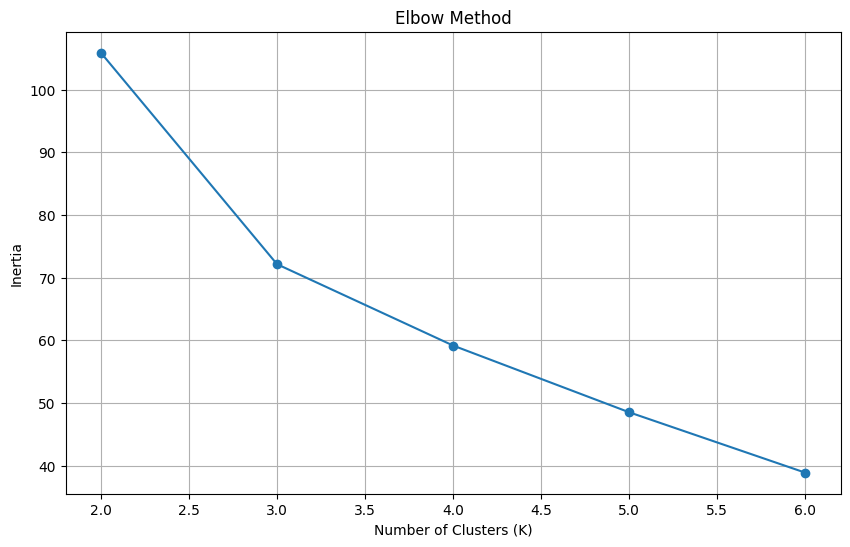

In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    list(K_range),
    inertia,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Inertia"
)

plt.title(
    "Elbow Method"
)

plt.grid(True)

plt.show()

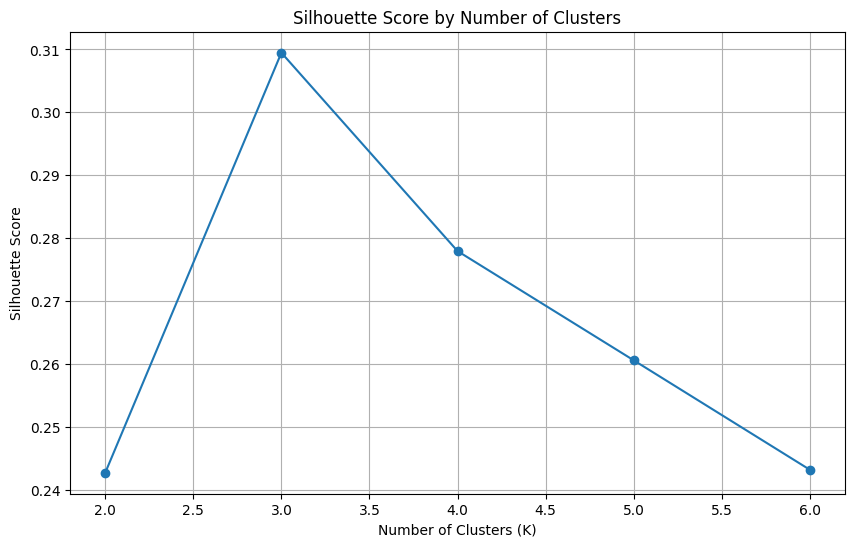

K=2: Silhouette=0.2427
K=3: Silhouette=0.3095
K=4: Silhouette=0.2779
K=5: Silhouette=0.2606
K=6: Silhouette=0.2432


In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Silhouette Score"
)

plt.title(
    "Silhouette Score by Number of Clusters"
)

plt.grid(True)

plt.show()

for k, score in zip(
    K_range,
    silhouette_scores
):

    print(
        f"K={k}: "
        f"Silhouette={score:.4f}"
    )

In [ ]:
best_k = list(K_range)[
    np.argmax(
        silhouette_scores
    )
]

print(
    "Recommended number of clusters:",
    best_k
)

Recommended number of clusters: 3


Train final K-Means

In [ ]:
# ============================================================
# FINAL K-MEANS MODEL
# ============================================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=50
)

master["cluster"] = (
    kmeans.fit_predict(
        X_scaled_cleaned
    )
)

print(
    master["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0     3
1    10
2     3
Name: count, dtype: int64


In [ ]:
cluster_profile = (
    master
    .groupby("cluster")[ml_features]
    .mean()
)

display(
    cluster_profile
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
cluster,,,,,,,,,,
0,"71,839.199","13,010.333","10,091.000",-1.000,-0.370,-2.967,75.733,0.012,99.633,-606.333
1,"41,608.616","6,989.700","5,596.100",-5.070,-0.347,-3.540,65.780,0.225,99.110,-230.400
2,"31,879.862","5,837.667","4,389.667",-14.567,-0.387,-5.033,64.300,0.998,79.367,-259.333


In [ ]:
cluster_profile_scaled = (
    pd.DataFrame(
        scaler.transform(
            cluster_profile
        ),
        columns=ml_features,
        index=cluster_profile.index
    )
)

display(
    cluster_profile_scaled
)

,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score
cluster,,,,,,,,,,
0,1.009,1.903,1.870,1.030,-0.403,0.468,1.480,-0.687,0.515,-1.001
1,-0.147,-0.340,-0.297,0.206,0.442,0.108,-0.281,-0.227,0.450,0.253
2,-0.519,-0.769,-0.879,-1.717,-1.070,-0.828,-0.543,1.444,-2.014,0.157


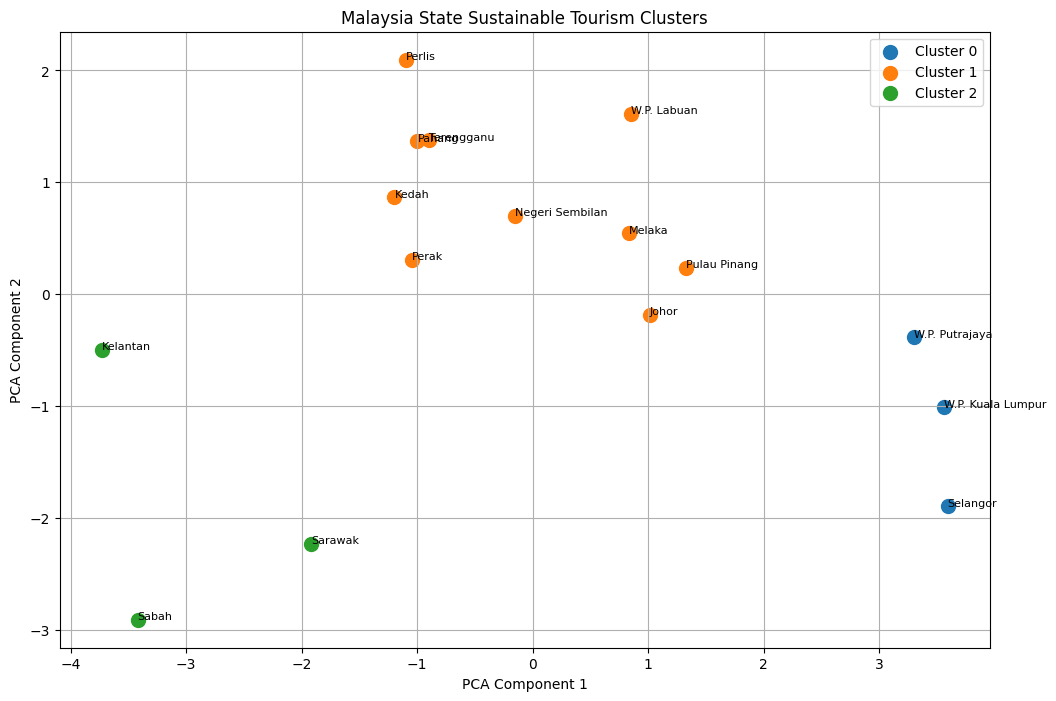

In [ ]:
# ============================================================
# PCA
# ============================================================

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_scaled_cleaned
)

master["PCA1"] = X_pca[:, 0]
master["PCA2"] = X_pca[:, 1]

plt.figure(
    figsize=(12, 8)
)

for cluster in sorted(
    master["cluster"].unique()
):

    subset = master[
        master["cluster"] == cluster
    ]

    plt.scatter(
        subset["PCA1"],
        subset["PCA2"],
        label=f"Cluster {cluster}",
        s=100
    )

    for _, row in subset.iterrows():

        plt.annotate(
            row["state"],
            (
                row["PCA1"],
                row["PCA2"]
            ),
            fontsize=8
        )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title(
    "Malaysia State Sustainable Tourism Clusters"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
cluster_states = master[
    [
        "state",
        "cluster"
    ]
].sort_values(
    "cluster"
)

display(
    cluster_states
)

,state,cluster
13,W.P. Kuala Lumpur,0
15,W.P. Putrajaya,0
9,Selangor,0
0,Johor,1
6,Pulau Pinang,1
1,Kedah,1
3,Melaka,1
4,Negeri Sembilan,1
14,W.P. Labuan,1
7,Perak,1


In [ ]:
# ============================================================
# DIMENSION SCORES
# ============================================================

from sklearn.preprocessing import MinMaxScaler

dimension_scaler = MinMaxScaler()

master["economic_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "gdp_per_capita",
                "income_mean",
                "income_median"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
master["social_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "poverty_score",
                "inequality_score",
                "unemployment_score",
                "labour_participation_rate"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
if "tourism_guests_score" in master.columns and "average_occupancy_rate" in master.columns:
    master["tourism_score"] = (
        dimension_scaler.fit_transform(
            master[
                [
                    "tourism_guests_score",
                    "average_occupancy_rate"
                ]
            ]
        ).mean(axis=1) * 100
    )
else:
    print("Tourism scores not available, setting tourism_score to 0.")
    master["tourism_score"] = 0

Tourism scores not available, setting tourism_score to 0.


In [ ]:
master["environment_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "forest_per_population",
                "treated_water_access",
                "water_pressure_score"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
# ============================================================
# SUSTAINABLE TOURISM READINESS INDEX
# ============================================================

# Check if tourism_score is available, if not, adjust weights or set it to 0
if "tourism_score" in master.columns:
    master["readiness_score"] = (
        master["economic_score"] * 0.25
        +
        master["social_score"] * 0.25
        +
        master["environment_score"] * 0.25
        +
        master["tourism_score"] * 0.25
    )
else:
    print("Tourism score not available. Calculating readiness score without it (equal weights). ")
    master["readiness_score"] = (
        master["economic_score"] * (1/3)
        +
        master["social_score"] * (1/3)
        +
        master["environment_score"] * (1/3)
    )

master["readiness_score"] = (
    master["readiness_score"]
    .round(2)
)

display(
    master
    .sort_values(
        "readiness_score",
        ascending=False
    )[
        [
            "state",
            "economic_score",
            "social_score",
            "environment_score",
            "tourism_score" if "tourism_score" in master.columns else "economic_score", # display placeholder if not present
            "readiness_score"
        ]
    ]
)

,state,economic_score,social_score,environment_score,tourism_score,readiness_score
13,W.P. Kuala Lumpur,99.426,61.682,60.675,0,55.450
15,W.P. Putrajaya,73.040,82.105,60.674,0,53.950
14,W.P. Labuan,50.462,63.031,66.291,0,44.950
9,Selangor,72.918,71.345,33.816,0,44.520
6,Pulau Pinang,43.044,64.545,58.695,0,41.570
5,Pahang,16.467,70.777,77.941,0,41.300
3,Melaka,34.796,65.558,62.470,0,40.710
0,Johor,36.909,61.760,55.303,0,38.490
10,Terengganu,25.750,55.872,67.148,0,37.190
4,Negeri Sembilan,23.984,53.435,63.880,0,35.320


In [ ]:
# Include tourism score in readiness index calculation
master["readiness_score"] = (
    master["economic_score"] * 0.25
    +
    master["social_score"] * 0.25
    +
    master["environment_score"] * 0.25
    +
    master["tourism_score"] * 0.25
)

In [ ]:
# ============================================================
# READINESS CATEGORY
# ============================================================

def readiness_category(score):

    if score >= 70:
        return "High"

    elif score >= 50:
        return "Medium"

    else:
        return "Emerging"


master["readiness_category"] = (
    master["readiness_score"]
    .apply(readiness_category)
)

display(
    master[
        [
            "state",
            "readiness_score",
            "readiness_category"
        ]
    ].sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,readiness_score,readiness_category
13,W.P. Kuala Lumpur,55.446,Medium
15,W.P. Putrajaya,53.955,Medium
14,W.P. Labuan,44.946,Emerging
9,Selangor,44.520,Emerging
6,Pulau Pinang,41.571,Emerging
5,Pahang,41.296,Emerging
3,Melaka,40.706,Emerging
0,Johor,38.493,Emerging
10,Terengganu,37.193,Emerging
4,Negeri Sembilan,35.325,Emerging


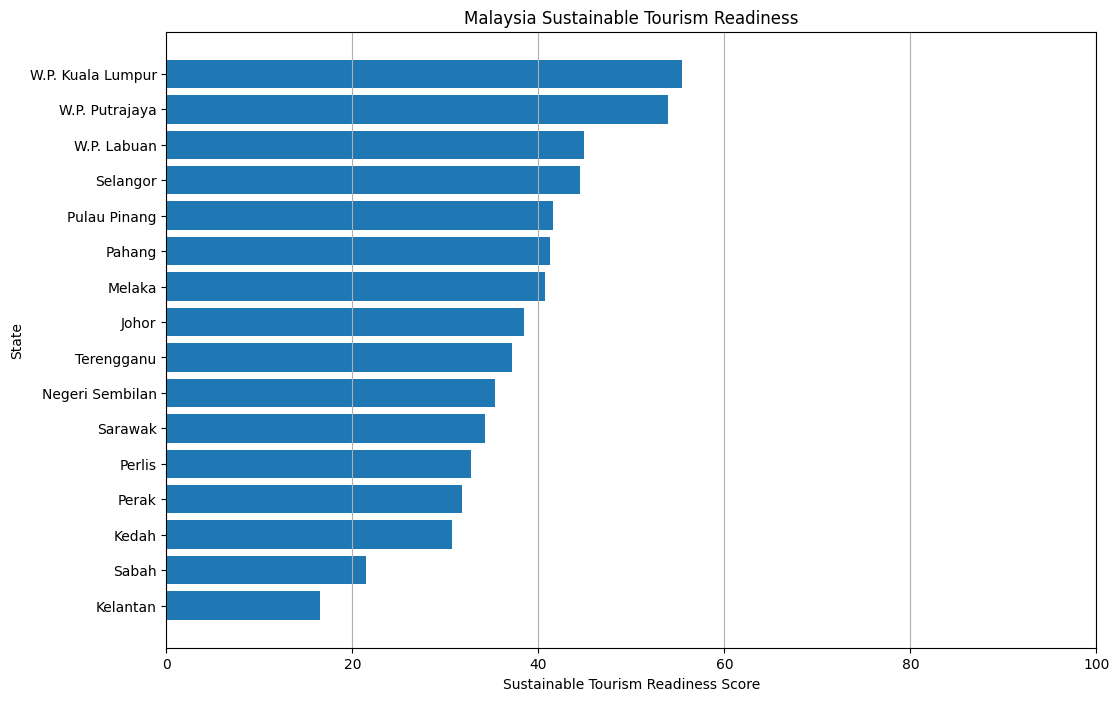

In [ ]:
ranking = (
    master[
        [
            "state",
            "readiness_score"
        ]
    ]
    .sort_values(
        "readiness_score",
        ascending=True
    )
)

plt.figure(
    figsize=(12, 8)
)

plt.barh(
    ranking["state"],
    ranking["readiness_score"]
)

plt.xlabel(
    "Sustainable Tourism Readiness Score"
)

plt.ylabel(
    "State"
)

plt.title(
    "Malaysia Sustainable Tourism Readiness"
)

plt.xlim(
    0,
    100
)

plt.grid(
    axis="x"
)

plt.show()

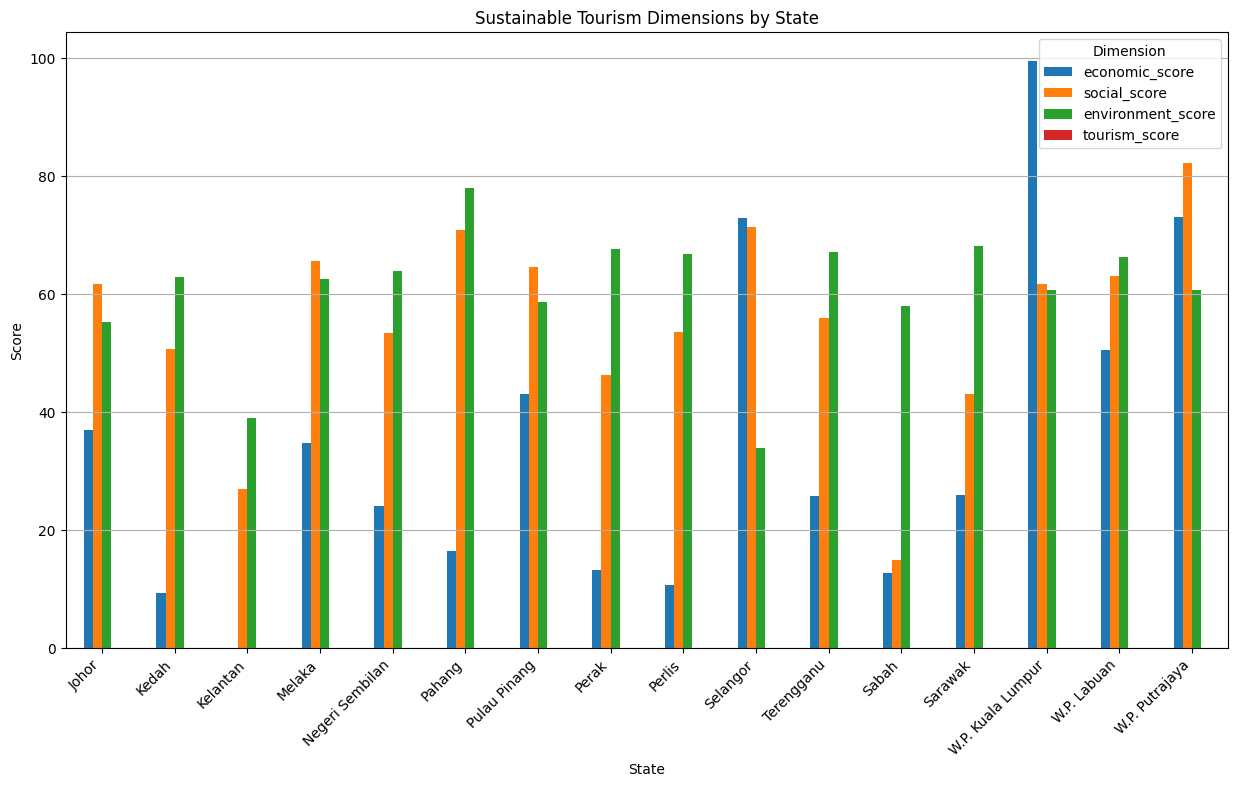

In [ ]:
score_columns = [
    "economic_score",
    "social_score",
    "environment_score"
]

# Add tourism_score if it exists
if "tourism_score" in master.columns:
    score_columns.append("tourism_score")

score_by_state = master[
    ["state"] + score_columns
].set_index("state")

score_by_state.plot(
    kind="bar",
    figsize=(15, 8)
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "State"
)

plt.title(
    "Sustainable Tourism Dimensions by State"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y"
)

plt.legend(
    title="Dimension"
)

plt.show()

In [ ]:
# score_columns.append("tourism_score") # This line is moved into Y1DtoCgO4wZg cell to ensure score_columns is defined when modified

ML classification

In [ ]:
# ============================================================
# RANDOM FOREST CLASSIFICATION
# ============================================================

# Ensure rf_features uses the complete ml_features list after tourism features are included
rf_features = ml_features

X_rf = master[
    rf_features
]

y_rf = master[
    "cluster"
]

In [ ]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced"
)

rf.fit(
    X_rf,
    y_rf
)

print(
    "Random Forest trained."
)

Random Forest trained.


In [ ]:
importance = pd.DataFrame({

    "feature":
    rf_features,

    "importance":
    rf.feature_importances_

})

importance = (
    importance
    .sort_values(
        "importance",
        ascending=False
    )
)

display(
    importance
)

,feature,importance
3,poverty_score,0.200
4,inequality_score,0.150
2,income_median,0.138
6,labour_participation_rate,0.134
8,treated_water_access,0.125
1,income_mean,0.121
7,forest_per_population,0.060
0,gdp_per_capita,0.028
5,unemployment_score,0.025
9,water_pressure_score,0.020


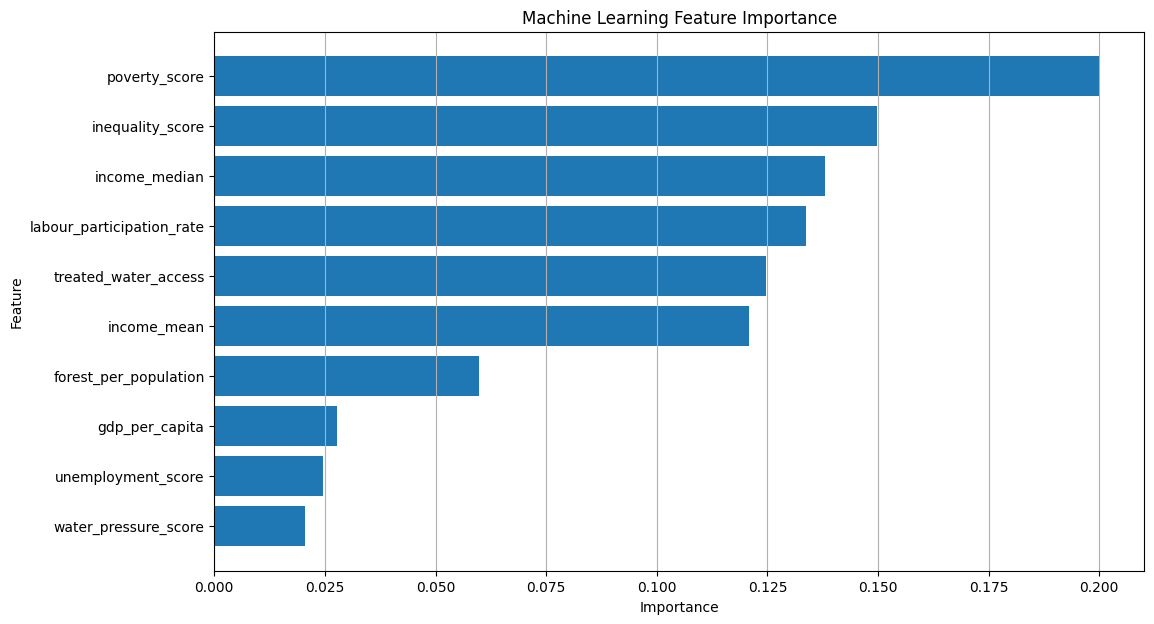

In [ ]:
plt.figure(
    figsize=(12, 7)
)

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Machine Learning Feature Importance"
)

plt.gca().invert_yaxis()

plt.grid(
    axis="x"
)

plt.show()

In [ ]:
# ============================================================
# CLUSTER INTERPRETATION
# ============================================================

cluster_scores = (
    master
    .groupby("cluster")
    [
        [
            "economic_score",
            "social_score",
            "environment_score",
            "readiness_score"
        ]
    ]
    .mean()
)

display(
    cluster_scores
)

,economic_score,social_score,environment_score,readiness_score
cluster,,,,
0,81.795,71.711,51.722,51.307
1,26.456,58.538,64.886,37.470
2,12.905,28.328,55.027,24.065


In [ ]:
cluster_names = {}

for cluster in cluster_scores.index:

    score = (
        cluster_scores
        .loc[
            cluster,
            "readiness_score"
        ]
    )

    if score >= 70:

        cluster_names[
            cluster
        ] = "High Readiness"

    elif score >= 50:

        cluster_names[
            cluster
        ] = "Moderate Readiness"

    else:

        cluster_names[
            cluster
        ] = "Emerging Readiness"


master["cluster_name"] = (
    master["cluster"]
    .map(cluster_names)
)

display(
    master[
        [
            "state",
            "cluster",
            "cluster_name"
        ]
    ]
)

,state,cluster,cluster_name
0,Johor,1,Emerging Readiness
1,Kedah,1,Emerging Readiness
2,Kelantan,2,Emerging Readiness
3,Melaka,1,Emerging Readiness
4,Negeri Sembilan,1,Emerging Readiness
5,Pahang,1,Emerging Readiness
6,Pulau Pinang,1,Emerging Readiness
7,Perak,1,Emerging Readiness
8,Perlis,1,Emerging Readiness
9,Selangor,0,Moderate Readiness


Final master dataset

In [ ]:
# ============================================================
# FINAL DATASET
# ============================================================

final_columns = [

    "state",

    # Raw socioeconomic
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty",

    # Population
    "population",

    # Tourism pressure
    "tourist_arrivals",
    "arrivals_per_1000_residents",

    # Economic
    "gdp",
    "gdp_per_capita",

    # Labour
    "unemployment_rate",
    "labour_participation_rate",

    # Environment
    "forest_reserve_area",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption",

    # Scores
    "economic_score",
    "social_score",
    "environment_score",
    "readiness_score",
    "readiness_category",

    # ML
    "cluster",
    "cluster_name"
]

# Add new tourism columns to final_columns if they exist in master
if "international_hotel_guests" in master.columns:
    final_columns.extend(["international_hotel_guests"])
# domestic_hotel_guests is removed as per user request
# if "domestic_hotel_guests" in master.columns:
#     final_columns.extend(["domestic_hotel_guests"])
if "average_occupancy_rate" in master.columns:
    final_columns.extend(["average_occupancy_rate"])
if "tourism_guests_score" in master.columns:
    final_columns.extend(["tourism_guests_score"])
if "tourism_score" in master.columns:
    final_columns.extend(["tourism_score"])

final_columns = [
    c for c in final_columns
    if c in master.columns
]

final_dataset = master[
    final_columns
].copy()

tourism_pressure_columns = [
    "state",
    "population",
    "tourist_arrivals",
    "arrivals_per_1000_residents",
    "readiness_score",
    "readiness_category"
]

# Add tourism related columns if they exist in final_dataset
if "international_hotel_guests" in final_dataset.columns:
    tourism_pressure_columns.append("international_hotel_guests")
# domestic_hotel_guests is removed as per user request
# if "domestic_hotel_guests" in final_dataset.columns:
#     tourism_pressure_columns.append("domestic_hotel_guests")
if "average_occupancy_rate" in final_dataset.columns:
    tourism_pressure_columns.append("average_occupancy_rate")

tourism_pressure_columns = [col for col in tourism_pressure_columns if col in final_dataset.columns]

tourism_pressure = final_dataset[
    tourism_pressure_columns
].copy()

display(
    final_dataset
    .sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,unemployment_rate,labour_participation_rate,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,economic_score,social_score,environment_score,readiness_score,readiness_category,cluster,cluster_name,tourism_score
13,W.P. Kuala Lumpur,13325,10234,7823,0.380,1.400,"1,961.200","240,517.538","122,637.945",3.800,72.700,68.000,99.550,389.500,234.500,99.426,61.682,60.675,55.446,Medium,0,Moderate Readiness,0
15,W.P. Putrajaya,13473,10056,8897,0.368,0.100,117.000,"61,746.204","38,249.522",1.300,77.700,0.000,99.550,389.500,234.500,73.040,82.105,60.674,53.955,Medium,0,Moderate Readiness,0
14,W.P. Labuan,8250,6904,4176,0.300,2.500,96.900,"7,962.511","82,172.456",6.900,67.400,0.000,100.000,19.000,33.000,50.462,63.031,66.291,44.946,Emerging,1,Emerging Readiness,0
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300","385,158.798","54,630.129",3.800,76.800,"250,208.000",99.800,"2,230.000","1,350.000",72.918,71.345,33.816,44.520,Emerging,0,Moderate Readiness,0
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900","112,281.052","64,495.980",2.700,70.100,"5,387.000",99.900,534.000,334.000,43.044,64.545,58.695,41.571,Emerging,1,Emerging Readiness,0
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300","61,746.204","38,249.522",2.300,64.600,"1,588,298.000",98.000,385.000,283.000,16.467,70.777,77.941,41.296,Emerging,1,Emerging Readiness,0
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398",1.700,69.800,"5,199.000",100.000,228.000,190.000,34.796,65.558,62.470,40.706,Emerging,1,Emerging Readiness,0
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376",3.200,71.100,"334,502.000",99.900,867.000,536.000,36.909,61.760,55.303,38.493,Emerging,1,Emerging Readiness,0
10,Terengganu,7248,5878,4796,0.326,6.200,"1,186.600","37,353.840","31,479.724",3.500,59.800,"540,309.000",96.000,286.000,173.000,25.750,55.872,67.148,37.193,Emerging,1,Emerging Readiness,0
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756",3.400,65.100,"155,143.000",99.900,307.000,231.000,23.984,53.435,63.880,35.325,Emerging,1,Emerging Readiness,0


In [ ]:
# The logic for adding tourism columns to final_columns has been integrated into S4LGmSqN5Uqs.

In [ ]:
import pandas as pd
# ============================================================
# HOTEL GUEST INTERNATIONAL
# ============================================================

hotel_guest_international = raw_data.get("hotel_guest_international")

if hotel_guest_international is not None:
    print(hotel_guest_international.columns.tolist())
    display(hotel_guest_international.head())

    # Rename 'YEAR ' column to 'year' for consistency
    if 'YEAR ' in hotel_guest_international.columns:
        hotel_guest_international = hotel_guest_international.rename(columns={'YEAR ': 'year'})
    elif 'YEAR' in hotel_guest_international.columns:
        hotel_guest_international = hotel_guest_international.rename(columns={'YEAR': 'year'})

    # Identify state columns by excluding 'year' and 'TOTAL '
    state_columns = [col for col in hotel_guest_international.columns if col not in ['year', 'TOTAL ']]

    # Melt the DataFrame to transform state columns into rows
    hotel_guest_international_melted = hotel_guest_international.melt(
        id_vars=['year'],
        value_vars=state_columns,
        var_name='state',
        value_name='value'
    )

    # Clean the state names after melting
    hotel_guest_international_melted['state'] = hotel_guest_international_melted['state'].str.strip()

    hotel_guest_international_2022 = hotel_guest_international_melted[
        hotel_guest_international_melted["year"] == 2022
    ].copy()

    # Group by state and sum the international guest arrivals
    hotel_guest_international_2022 = (
        hotel_guest_international_2022
        .groupby("state", as_index=False)["value"]
        .sum()
        .rename(columns={
            "value": "international_hotel_guests"
        })
    )
else:
    print("Hotel guest international data not available. Creating empty DataFrame.")
    hotel_guest_international_2022 = pd.DataFrame({'state': [], 'international_hotel_guests': []})

display(hotel_guest_international_2022)

['YEAR ', 'KUALA LUMPUR', 'PUTRAJAYA', 'SELANGOR', 'PENANG', 'PERAK', 'KEDAH', 'PERLIS', 'N. SEMBILAN', 'MELAKA', 'JOHOR', 'PAHANG ', 'TERENGGANU ', 'KELANTAN ', 'SABAH ', 'LABUAN ', 'SARAWAK ', 'TOTAL ']


,YEAR,KUALA LUMPUR,PUTRAJAYA,SELANGOR,PENANG,PERAK,KEDAH,PERLIS,N. SEMBILAN,MELAKA,JOHOR,PAHANG,TERENGGANU,KELANTAN,SABAH,LABUAN,SARAWAK,TOTAL
0,2015,"9,341,801","151,740","1,613,299","2,879,899","265,794","1,207,824","5,921","456,013","1,809,489","2,565,092","2,328,815","187,388","58,327","1,986,136","114,140","599,400","25,571,078"
1,2016,"9,436,404","166,473","1,624,265","2,911,783","267,517","1,281,471","5,946","459,966","1,804,544","2,581,983","2,369,945","192,530","57,664","2,036,610","111,815","599,985","25,908,901"
2,2017,"10,717,479","177,602","1,688,659","2,911,429","267,245","1,407,261","5,943","461,788","1,704,386","2,624,972","2,563,991","188,044","57,337","2,548,491","105,710","599,812","28,030,149"
3,2018,"11,602,079","188,740","1,998,361","3,016,491","291,253","1,589,344","5,910","459,279","1,555,103","2,615,254","2,686,594","179,556","54,074","3,108,364","89,643","560,512","30,000,557"
4,2019,"10,931,619","178,498","1,866,153","2,848,750","293,256","1,583,215","5,700","459,539","1,465,372","2,548,685","2,754,449","179,324","49,211","3,057,376","75,447","539,599","28,836,193"


,state,international_hotel_guests
0,JOHOR,"2,039,675"
1,KEDAH,"589,439"
2,KELANTAN,"36,969"
3,KUALA LUMPUR,"4,281,244"
4,LABUAN,"31,025"
5,MELAKA,"536,249"
6,N. SEMBILAN,"89,048"
7,PAHANG,"1,689,554"
8,PENANG,"1,256,628"
9,PERAK,"333,306"


In [ ]:
import pandas as pd
# ============================================================
# HOTEL GUEST DOMESTIC (REMOVED)
# ============================================================
print("Domestic hotel guest data processing skipped as per user request.")
hotel_guest_domestic_2022 = pd.DataFrame({'state': [], 'domestic_hotel_guests': []})
display(hotel_guest_domestic_2022)

Domestic hotel guest data processing skipped as per user request.


,state,domestic_hotel_guests


In [ ]:
# ============================================================
# HOTEL AVERAGE OCCUPANCY RATE (AOR)
# ============================================================

hotel_aor = raw_data.get("hotel_aor")

if hotel_aor is not None:
    # Clean column names: strip whitespace and convert 'YEAR ' to 'year'
    hotel_aor.columns = hotel_aor.columns.str.strip()
    if 'YEAR' in hotel_aor.columns:
        hotel_aor = hotel_aor.rename(columns={'YEAR': 'year'})

    print(hotel_aor.columns.tolist())
    display(hotel_aor.head())

    # Identify state columns by excluding 'year' and 'TOTAL'
    state_columns = [col for col in hotel_aor.columns if col not in ['year', 'TOTAL']]

    # Melt the DataFrame to transform state columns into rows
    hotel_aor_melted = hotel_aor.melt(
        id_vars=['year'],
        value_vars=state_columns,
        var_name='state',
        value_name='value'
    )

    # Convert 'value' to numeric, handling potential non-numeric entries
    hotel_aor_melted['value'] = pd.to_numeric(hotel_aor_melted['value'], errors='coerce')

    # Clean the state names after melting and standardize capitalization for merging
    hotel_aor_melted['state'] = (
        hotel_aor_melted['state'].str.strip()
        .str.title().replace(STATE_MAP)
    )

    hotel_aor_2022 = hotel_aor_melted[
        hotel_aor_melted["year"] == 2022
    ].copy()

    # Group by state and calculate the mean average occupancy rate
    hotel_aor_2022 = (
        hotel_aor_2022
        .groupby("state", as_index=False)["value"]
        .mean()
        .rename(columns={
            "value": "average_occupancy_rate"
        })
    )
else:
    print("Hotel AOR data not available. Creating empty DataFrame.")
    hotel_aor_2022 = pd.DataFrame({'state': [], 'average_occupancy_rate': []})

display(hotel_aor_2022)

['year', 'KUALA LUMPUR', 'PUTRAJAYA', 'SELANGOR', 'PENANG', 'PERAK', 'KEDAH', 'PERLIS', 'N. SEMBILAN', 'MELAKA', 'JOHOR', 'PAHANG', 'TERENGGANU', 'KELANTAN', 'SABAH', 'LABUAN', 'SARAWAK', 'TOTAL']


,year,KUALA LUMPUR,PUTRAJAYA,SELANGOR,PENANG,PERAK,KEDAH,PERLIS,N. SEMBILAN,MELAKA,JOHOR,PAHANG,TERENGGANU,KELANTAN,SABAH,LABUAN,SARAWAK,TOTAL
0,2015,67.100,65.700,64.700,63.700,51.300,54.900,44.400,47.900,63.300,58.500,79.300,48.700,40.900,64.200,66.200,57.900,61.900
1,2016,66.100,70.600,62.400,63.900,49.000,59.500,36.500,52.800,59.900,61.000,74.600,45.000,43.800,64.500,55.300,53.400,60.900
2,2017,66.100,73.900,60.300,62.100,46.300,60.300,35.400,55.700,60.000,62.500,75.700,45.200,43.800,65.300,52.600,52.600,60.600
3,2018,63.300,72.100,57.200,62.200,44.100,56.100,31.000,54.200,57.300,58.700,78.800,39.900,44.100,67.200,46.200,48.900,60.800
4,2019,59.900,64.200,56.400,56.500,43.900,55.700,36.000,51.900,51.700,57.300,79.400,41.300,43.400,65.800,42.200,46.100,58.800


,state,average_occupancy_rate
0,Johor,48.300
1,Kedah,32.500
2,Kelantan,46.400
3,Melaka,40.100
4,Negeri Sembilan,38.700
5,Pahang,46.100
6,Perak,54.800
7,Perlis,42.000
8,Pulau Pinang,44.100
9,Sabah,45.200


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
tourism_cols_to_drop = [
    "international_hotel_guests",
    "average_occupancy_rate"
]

# Drop any existing tourism-related columns (including those with _x, _y suffixes) from master
# We keep checking for domestic_hotel_guests here in case it was merged in a previous run
for col_name in ["international_hotel_guests", "domestic_hotel_guests", "average_occupancy_rate"]:
    for suffix in ['', '_x', '_y']:
        full_col_name = f"{col_name}{suffix}"
        if full_col_name in master.columns:
            master = master.drop(columns=[full_col_name])

# Ensure state columns are clean before merging
master["state"] = master["state"].astype(str).str.strip()
hotel_guest_international_2022["state"] = hotel_guest_international_2022["state"].astype(str).str.strip().str.title().replace(STATE_MAP)
hotel_aor_2022["state"] = hotel_aor_2022["state"].astype(str).str.strip()

# Hotel Guest International
print("Merging international hotel guests...")
print(f"States in master: {sorted(master['state'].unique())}")
print(f"States in hotel_guest_international_2022: {sorted(hotel_guest_international_2022['state'].unique())}")
master = master.merge(
    hotel_guest_international_2022,
    on="state",
    how="left"
)

# Hotel Guest Domestic - REMOVED AS PER USER REQUEST
# master = master.merge(
#     hotel_guest_domestic_2022,
#     on="state",
#     how="left"
# )

# Hotel Average Occupancy Rate
print("Merging average occupancy rate...")
master = master.merge(
    hotel_aor_2022,
    on="state",
    how="left"
)

# Ensure the columns exist before attempting to fill NaN values
for col in tourism_cols_to_drop:
    if col not in master.columns:
        master[col] = 0

# Fill NaN values for new tourism features with 0, assuming missing means no activity
master[
    tourism_cols_to_drop
] = master[
    tourism_cols_to_drop
].fillna(0)

# CRITICAL CHECK: Ensure 'international_hotel_guests' is not all zeros
if 'international_hotel_guests' in master.columns and (master['international_hotel_guests'] == 0).all():
    raise ValueError("Error: 'international_hotel_guests' column is all zeros after merge, which contradicts requirements.")

print("Master dataset with new tourism features:")
display(master.head())

Merging international hotel guests...
States in master: ['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']
States in hotel_guest_international_2022: ['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']
Merging average occupancy rate...
Master dataset with new tourism features:


,state,income_mean,income_median,expenditure_mean,gini,poverty,population,gdp,gdp_per_capita,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,unemployment_rate,labour_participation_rate,income_per_capita,expenditure_income_ratio,gdp_income_ratio,water_security,forest_per_population,poverty_score,inequality_score,unemployment_score,water_pressure_score,cluster,PCA1,PCA2,economic_score,social_score,tourism_score,environment_score,readiness_score,readiness_category,cluster_name,international_hotel_guests,average_occupancy_rate
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300","142,369.692","35,342.376","334,502.000",99.900,867.000,536.000,3.200,71.100,8517,0.627,4.150,99.900,0.083,-4.600,-0.366,-3.200,-536.000,1,1.011,-0.184,36.909,61.760,0,55.303,38.493,Emerging,Emerging Readiness,"2,039,675",48.300
1,Kedah,5550,4402,3765,0.359,9.000,"2,163.100","50,982.123","23,569.009","341,976.000",98.300,560.000,217.000,3.000,64.200,5550,0.678,4.247,98.300,0.158,-9.000,-0.359,-3.000,-217.000,1,-1.197,0.867,9.284,50.710,0,62.803,30.699,Emerging,Emerging Readiness,"589,439",32.500
2,Kelantan,4885,3614,3505,0.385,13.200,"1,830.600","26,934.566","14,713.518","629,881.000",73.900,162.000,77.000,3.600,56.300,4885,0.718,3.012,73.900,0.344,-13.200,-0.385,-3.600,-77.000,2,-3.727,-0.496,0.000,26.938,0,39.012,16.488,Emerging,Emerging Readiness,"36,969",46.400
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600","45,579.035","45,190.398","5,199.000",100.000,228.000,190.000,1.700,69.800,8057,0.708,5.609,100.000,0.005,-4.200,-0.370,-1.700,-190.000,1,0.831,0.543,34.796,65.558,0,62.470,40.706,Emerging,Emerging Readiness,"536,249",40.100
4,Negeri Sembilan,6788,5226,4678,0.369,4.400,"1,207.900","50,939.264","42,171.756","155,143.000",99.900,307.000,231.000,3.400,65.100,6788,0.689,6.213,99.900,0.128,-4.400,-0.369,-3.400,-231.000,1,-0.154,0.700,23.984,53.435,0,63.880,35.325,Emerging,Emerging Readiness,"89,048",38.700


In [ ]:
tourism_features = [
    "international_hotel_guests",
    "domestic_hotel_guests",
    "average_occupancy_rate"
]

In [ ]:
import numpy as np
# ============================================================
# TOURISM GUESTS SCORE (population-adjusted)
# ============================================================

# Use guests per resident, not a raw count, so large-population states
# aren't scored high purely for their size.

# Convert to numeric, handling potential non-numeric strings and filling NaNs
master["international_hotel_guests"] = pd.to_numeric(
    master["international_hotel_guests"].astype(str).str.replace(',',''),
    errors='coerce'
).fillna(0)

master["population"] = pd.to_numeric(
    master["population"].astype(str).str.replace(',',''),
    errors='coerce'
).fillna(0)

# Calculate tourism_intensity, handling potential division by zero
# Replace 0 population with NaN so division results in NaN, then fill with 0
master["tourism_intensity"] = (
    master["international_hotel_guests"] /
    master["population"].replace(0, np.nan)
).fillna(0)

master["tourism_guests_score"] = master["tourism_intensity"]

In [ ]:
ml_features = [

    # Economic
    "gdp_per_capita",
    "income_mean",
    "income_median",

    # Social
    "poverty_score",
    "inequality_score",
    "unemployment_score",
    "labour_participation_rate",

    # Environmental
    "forest_per_population",
    "treated_water_access",
    "water_pressure_score",

    # Tourism
    "tourism_guests_score",
    "average_occupancy_rate"
]

X = master[
    ml_features
].copy()

print(
    X.shape
)

display(X.head())

(16, 12)


,gdp_per_capita,income_mean,income_median,poverty_score,inequality_score,unemployment_score,labour_participation_rate,forest_per_population,treated_water_access,water_pressure_score,tourism_guests_score,average_occupancy_rate
0,"35,342.376",8517,6879,-4.600,-0.366,-3.200,71.100,0.083,99.900,-536.000,506.336,48.300
1,"23,569.009",5550,4402,-9.000,-0.359,-3.000,64.200,0.158,98.300,-217.000,272.497,32.500
2,"14,713.518",4885,3614,-13.200,-0.385,-3.600,56.300,0.344,73.900,-77.000,20.195,46.400
3,"45,190.398",8057,6210,-4.200,-0.370,-1.700,69.800,0.005,100.000,-190.000,531.677,40.100
4,"42,171.756",6788,5226,-4.400,-0.369,-3.400,65.100,0.128,99.900,-231.000,73.721,38.700


In [ ]:
master["tourism_guests_score"] = pd.to_numeric(master["tourism_guests_score"].astype(str).str.replace(',', ''), errors='coerce').fillna(0)
master["average_occupancy_rate"] = pd.to_numeric(master["average_occupancy_rate"].astype(str).str.replace(',', ''), errors='coerce').fillna(0)

master["tourism_score"] = (
    dimension_scaler.fit_transform(
        master[
            [
                "tourism_guests_score",
                "average_occupancy_rate"
            ]
        ]
    ).mean(axis=1) * 100
)

In [ ]:
# Include tourism score in readiness index calculation
master["readiness_score"] = (
    master["economic_score"] * 0.25
    +
    master["social_score"] * 0.25
    +
    master["environment_score"] * 0.25
    +
    master["tourism_score"] * 0.25
)

master["readiness_score"] = (
    master["readiness_score"]
    .round(2)
)

display(
    master
    .sort_values(
        "readiness_score",
        ascending=False
    )[
        [
            "state",
            "economic_score",
            "social_score",
            "environment_score",
            "tourism_score",
            "readiness_score"
        ]
    ]
)

,state,economic_score,social_score,environment_score,tourism_score,readiness_score
13,W.P. Kuala Lumpur,99.426,61.682,60.675,83.133,76.230
15,W.P. Putrajaya,73.040,82.105,60.674,48.341,66.040
9,Selangor,72.918,71.345,33.816,47.342,56.360
5,Pahang,16.467,70.777,77.941,51.086,54.070
6,Pulau Pinang,43.044,64.545,58.695,39.575,51.470
0,Johor,36.909,61.760,55.303,43.036,49.250
10,Terengganu,25.750,55.872,67.148,47.097,48.970
12,Sarawak,25.994,43.092,68.046,55.393,48.130
14,W.P. Labuan,50.462,63.031,66.291,12.636,48.110
3,Melaka,34.796,65.558,62.470,27.155,47.490


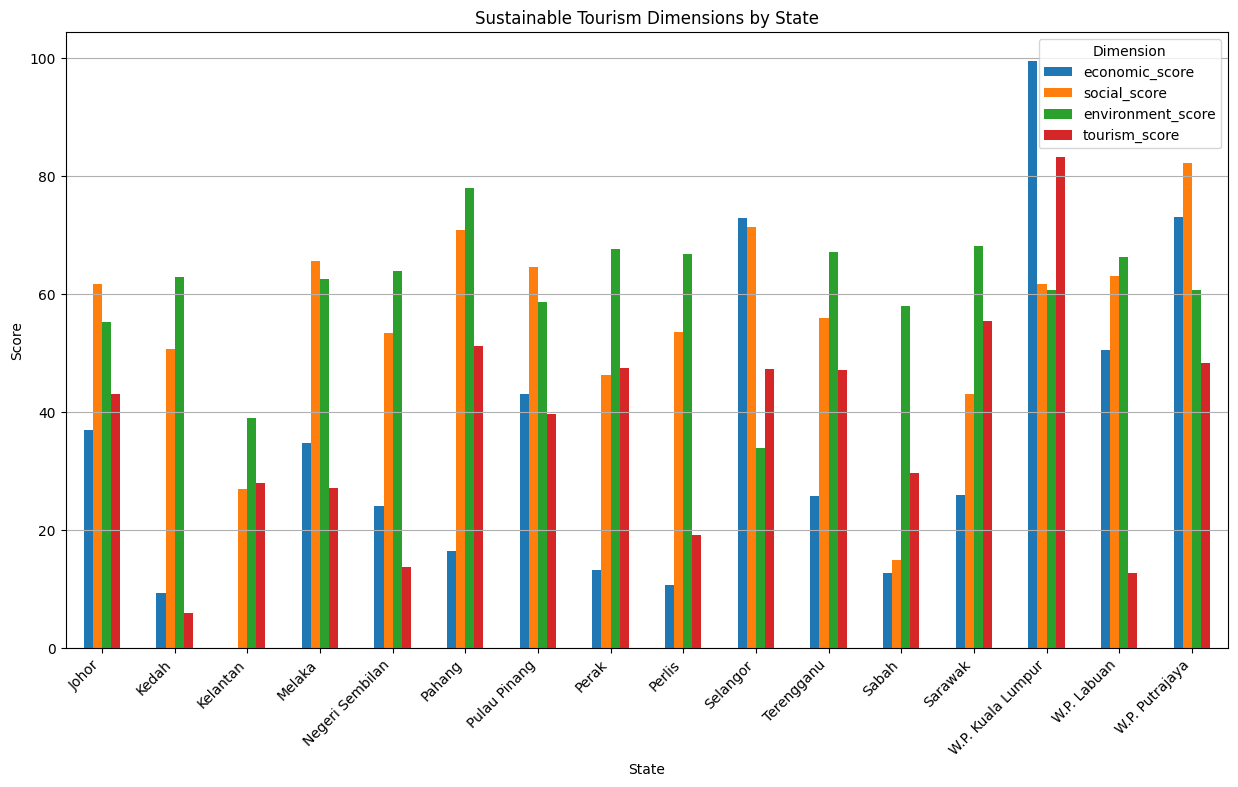

In [ ]:
score_columns = [
    "economic_score",
    "social_score",
    "environment_score",
    "tourism_score"
]

score_by_state = master[
    ["state"] + score_columns
].set_index("state")

score_by_state.plot(
    kind="bar",
    figsize=(15, 8)
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "State"
)

plt.title(
    "Sustainable Tourism Dimensions by State"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y"
)

plt.legend(
    title="Dimension"
)

plt.show()

In [ ]:
# Add new tourism columns to final_columns
final_columns = [

    "state",

    # Raw socioeconomic
    "income_mean",
    "income_median",
    "expenditure_mean",
    "gini",
    "poverty",

    # Population
    "population",

    # Tourism data
    "international_hotel_guests",
    # "domestic_hotel_guests", # Removed as per user request
    "average_occupancy_rate",
    "tourism_intensity", # Added as per user request

    # Economic
    "gdp",
    "gdp_per_capita",

    # Labour
    "unemployment_rate",
    "labour_participation_rate",

    # Environment
    "forest_reserve_area",
    "treated_water_access",
    "domestic_water_consumption",
    "nondomestic_water_consumption",

    # Scores
    "economic_score",
    "social_score",
    "environment_score",
    "tourism_score",
    "readiness_score",
    "readiness_category",

    # ML
    "cluster",
    "cluster_name"
]

final_columns = [
    c for c in final_columns
    if c in master.columns
]

final_dataset = master[
    final_columns
].copy()

tourism_pressure = final_dataset[
    [
        "state",
        "population",
        "international_hotel_guests",
        # "domestic_hotel_guests", # Removed as per user request
        "average_occupancy_rate",
        "tourism_intensity", # Added as per user request
        "readiness_score",
        "readiness_category"
    ]
].copy()

display(
    final_dataset
    .sort_values(
        "readiness_score",
        ascending=False
    )
)

,state,income_mean,income_median,expenditure_mean,gini,poverty,population,international_hotel_guests,average_occupancy_rate,tourism_intensity,gdp,gdp_per_capita,unemployment_rate,labour_participation_rate,forest_reserve_area,treated_water_access,domestic_water_consumption,nondomestic_water_consumption,economic_score,social_score,environment_score,tourism_score,readiness_score,readiness_category,cluster,cluster_name
13,W.P. Kuala Lumpur,13325,10234,7823,0.380,1.400,"1,961.200",4281244,49.000,"2,182.972","240,517.538","122,637.945",3.800,72.700,68.000,99.550,389.500,234.500,99.426,61.682,60.675,83.133,76.230,Medium,0,Moderate Readiness
15,W.P. Putrajaya,13473,10056,8897,0.368,0.100,117.000,56610,51.200,483.846,"61,746.204","38,249.522",1.300,77.700,0.000,99.550,389.500,234.500,73.040,82.105,60.674,48.341,66.040,Medium,0,Moderate Readiness
9,Selangor,12233,9983,6770,0.361,1.500,"7,050.300",1572497,53.700,223.040,"385,158.798","54,630.129",3.800,76.800,"250,208.000",99.800,"2,230.000","1,350.000",72.918,71.345,33.816,47.342,56.360,Emerging,0,Moderate Readiness
5,Pahang,5777,4753,4107,0.308,6.300,"1,614.300",1689554,46.100,"1,046.617","61,746.204","38,249.522",2.300,64.600,"1,588,298.000",98.000,385.000,283.000,16.467,70.777,77.941,51.086,54.070,Emerging,1,Emerging Readiness
6,Pulau Pinang,8267,6502,5322,0.371,2.000,"1,740.900",1256628,44.100,721.827,"112,281.052","64,495.980",2.700,70.100,"5,387.000",99.900,534.000,334.000,43.044,64.545,58.695,39.575,51.470,Emerging,1,Emerging Readiness
0,Johor,8517,6879,5342,0.366,4.600,"4,028.300",2039675,48.300,506.336,"142,369.692","35,342.376",3.200,71.100,"334,502.000",99.900,867.000,536.000,36.909,61.760,55.303,43.036,49.250,Emerging,1,Emerging Readiness
10,Terengganu,7248,5878,4796,0.326,6.200,"1,186.600",86846,55.300,73.189,"37,353.840","31,479.724",3.500,59.800,"540,309.000",96.000,286.000,173.000,25.750,55.872,67.148,47.097,48.970,Emerging,1,Emerging Readiness
12,Sarawak,6457,4978,3915,0.382,10.800,"2,473.500",618251,57.400,249.950,"140,698.831","56,882.487",3.800,67.500,"3,964,880.000",83.700,602.000,463.000,25.994,43.092,68.046,55.393,48.130,Emerging,2,Emerging Readiness
14,W.P. Labuan,8250,6904,4176,0.300,2.500,96.900,31025,35.300,320.175,"7,962.511","82,172.456",6.900,67.400,0.000,100.000,19.000,33.000,50.462,63.031,66.291,12.636,48.110,Emerging,1,Emerging Readiness
3,Melaka,8057,6210,5707,0.370,4.200,"1,008.600",536249,40.100,531.677,"45,579.035","45,190.398",1.700,69.800,"5,199.000",100.000,228.000,190.000,34.796,65.558,62.470,27.155,47.490,Emerging,1,Emerging Readiness


In [ ]:
# ============================================================
# EXPORT POWER BI FILES
# ============================================================

final_dataset.to_csv(
    "outputs/Malaysia_Sustainable_Tourism_Master.csv",
    index=False
)

tourism_demand_forecast.to_csv(
    "outputs/Tourism_Demand_Forecast.csv",
    index=False
)

tourism_pressure.to_csv(
    "outputs/State_Tourism_Pressure.csv",
    index=False
)

importance.to_csv(
    "outputs/ML_Feature_Importance.csv",
    index=False
)

cluster_profile.to_csv(
    "outputs/ML_Cluster_Profile.csv"
)

cluster_states.to_csv(
    "outputs/ML_State_Clusters.csv",
    index=False
)

results = pd.DataFrame({
    "Metric": [
        "Number of states",
        "Number of ML clusters",
        "Silhouette score"
    ],

    "Value": [
        master["state"].nunique(),
        best_k,
        max(silhouette_scores)
    ]
})

results.to_csv(
    "outputs/ML_Model_Summary.csv",
    index=False
)

print(
    "Power BI files created."
)

Power BI files created.


In [ ]:
import os

file_path = '/content/2015 2022 MALAYSIA INTERNATIONAL HOTEL GUESTS  .csv'
if os.path.exists(file_path):
    print(f"The file '{file_path}' exists.")
else:
    print(f"The file '{file_path}' does not exist.")

The file '/content/2015 2022 MALAYSIA INTERNATIONAL HOTEL GUESTS  .csv' does not exist.


In [ ]:
import shutil

shutil.make_archive(
    "Malaysia_Sustainable_Tourism_Project",
    "zip",
    "outputs"
)

print(
    "ZIP created:"
)

print(
    "Malaysia_Sustainable_Tourism_Project.zip"
)

ZIP created:
Malaysia_Sustainable_Tourism_Project.zip


In [ ]:
print("Final dataset exported to outputs/Malaysia_Sustainable_Tourism_Master.csv")
print("Model summary exported to outputs/ML_Model_Summary.csv")

Final dataset exported to outputs/Malaysia_Sustainable_Tourism_Master.csv
Model summary exported to outputs/ML_Model_Summary.csv


In [ ]:
display(master[[
    "state",
    "international_hotel_guests",
    "average_occupancy_rate"
]].head(16))

,state,international_hotel_guests,average_occupancy_rate
0,Johor,2039675,48.300
1,Kedah,589439,32.500
2,Kelantan,36969,46.400
3,Melaka,536249,40.100
4,Negeri Sembilan,89048,38.700
5,Pahang,1689554,46.100
6,Pulau Pinang,1256628,44.100
7,Perak,333306,54.800
8,Perlis,4709,42.000
9,Selangor,1572497,53.700


If you need domestic guest data for 2022, you might need to find an alternative data source, as the current file doesn't provide this information.

In [ ]:
print(master[['state','international_hotel_guests','population','tourism_intensity']])

                state  international_hotel_guests  population  \
0               Johor                     2039675   4,028.300   
1               Kedah                      589439   2,163.100   
2            Kelantan                       36969   1,830.600   
3              Melaka                      536249   1,008.600   
4     Negeri Sembilan                       89048   1,207.900   
5              Pahang                     1689554   1,614.300   
6        Pulau Pinang                     1256628   1,740.900   
7               Perak                      333306   2,514.400   
8              Perlis                        4709     289.800   
9            Selangor                     1572497   7,050.300   
10         Terengganu                       86846   1,186.600   
11              Sabah                      677103   3,414.900   
12            Sarawak                      618251   2,473.500   
13  W.P. Kuala Lumpur                     4281244   1,961.200   
14        W.P. Labuan    

In [ ]:
# This cell is commented out as 'tourism_guests_score' is correctly calculated with population adjustment in cell 'N9Cg7B0Y7v9F'.
# if "international_hotel_guests" not in master.columns:
#     print("Warning: 'international_hotel_guests' column not found in master. Initializing with zeros.")
#     master["international_hotel_guests"] = 0

# master["tourism_guests_score"] = (
#     master["international_hotel_guests"]
# )